# 02b — Data quality before and after cleaning (stage 3b)

**Purpose.** A full examination of the quality of all 27 tags before and after cleaning, with the
evidence behind every cleaning threshold. Stage 3 (`02_eda.ipynb`) covered the corrections of the
rebuild (time base, clocks, the 2025 data source) and the target; this notebook covers the data
themselves: what is wrong in them, why each rule of `configs/cleaning_policy.yaml` is set where it
is, what cleaning changed, and what the cleaned data imply for modelling.

**Before and after.** "Before cleaning" is the stage-4 output: clock-corrected, true-UTC minutes
with the 2025 polled data rebuilt — exactly what the cleaning rules see. "After cleaning" is the
stage-5 output. The raw export (stage 2) is used where the export format itself is the subject.

**Rules.** EDA changes no data. Every threshold is judged on the **train split only**
(UTC ≤ 2024-01-31); analyses over the whole period are descriptive and say so; the split
comparison (Q31) is used for no decision. Each code cell runs one analysis of
`solarpv.eda.quality` and is followed by a note: *what the cell shows*, *what it means*, and
*the rule or decision it supports*. The numbers in the notes come from the manifest written by the
same functions (`python -m solarpv.eda.quality`).

**Findings fed back into cleaning.** This analysis found three problems, which were fixed in
stage 5 before this notebook was run (`docs/stage3b_quality_eda_plan.md`, PROJECT_MASTER.md):
F-20, a drifting curtailment setpoint that did not limit output (Q15); F-21, pyranometer faults
within a day that a daily check missed (Q13); and F-22, partial inverter outages that no flag
marked (Q16, new flag F3).

**Structure.** Part A — the export as delivered (Q01–Q04). Part B — the evidence for each cleaning
threshold (Q05–Q17). Part C — what cleaning changed (Q18–Q22). Part D — the cleaned data for
modelling (Q23–Q31). A summary table closes the notebook.

In [1]:
import pandas as pd

from solarpv.eda import quality as Q

pd.set_option("display.max_columns", 40)
d = Q.load()  # stage-4 and stage-5 minutes and hours, sun position, clear-sky POA, policy
print(f"stage 4 minutes: {d.s4.shape}, stage 5 minutes: {d.s5.shape}, hours: {d.h5.shape}")
print(f"train minutes: {int(d.train.sum()):,}; daytime minutes (sun > 10 deg): "
      f"{int(d.daytime.sum()):,}")

stage 4 minutes: (1971360, 31), stage 5 minutes: (1971360, 48), hours: (32856, 45)
train minutes: 1,271,700; daytime minutes (sun > 10 deg): 846,571


**Loaded.** The minute data before (stage 4) and after (stage 5) cleaning on the full
true-UTC grid, the hourly tables, the sun elevation and clear-sky in-plane irradiance of every
minute (pvlib, measured orientation 20°/180°), the split of every minute and the cleaning policy.
"Daytime" in Parts A–C is the policy's definition (sun above 10° at the minute); the hourly
analyses use the evaluation mask (sun above 5° at mid-hour, F-02).

## Part A — The export as delivered

### Q01 — Inventory of the 27 tags

**Question.** What does each tag measure, what is its role in the project, and how complete is it? **Data.** Raw export (stage 2) for the value statistics; NaN counts in stages 2, 4 and 5.

In [2]:
r = Q.q01_inventory(d)  # units, roles, ranges and gaps of every tag
r.show()

,column,group,unit,logger,role,role_class,min,p1,p50,p99,max,distinct_values,non_integer_share,nan_raw,nan_stage4,nan_stage5
0,site_total_AC_kW,power,kW,derived,"target: inverter 1 + inverter 2, minute by minute",target,0.00,0.00,1.39,2664.55,42162.96,983530,NaN,NaN,330,6037
1,s01_inv1_AC_kW,power,kW,inverter,target component; model input as past-day lags,target,0.00,0.00,0.00,1326.03,40825.09,921124,NaN,0.0,239,5938
2,s01_inv2_AC_kW,power,kW,inverter,target component; model input as past-day lags,target,0.00,0.00,0.00,1349.66,12045.41,920633,NaN,0.0,265,5914
3,s01_inv1_DC_kW,power,kW,inverter,"QA only: rule R6, clock check (measured at the...",QA only,0.00,0.00,0.00,1381.55,28150.24,879597,NaN,0.0,239,10438
4,s01_inv2_DC_kW,power,kW,inverter,"QA only: rule R6, clock check (measured at the...",QA only,0.00,0.00,0.00,1408.01,18027.69,880596,NaN,0.0,265,3486
5,s01_inv1_AC_kVar,power,kVar,inverter,"not used: reactive power, set by the grid oper...",not used,-1445.64,-290.65,0.00,844.42,8226.72,919433,NaN,0.0,213,213
6,s01_inv2_AC_kVar,power,kVar,inverter,"not used: reactive power, set by the grid oper...",not used,-774.00,-297.40,0.00,872.73,5300.71,919246,NaN,0.0,291,291
7,s01_inv1_PF,power,power factor,inverter,not used: follows the reactive-power setpoint ...,not used,0.00,0.81,1.00,1.00,1.00,73977,NaN,0.0,239,239
8,s01_inv2_PF,power,power factor,inverter,not used: follows the reactive-power setpoint ...,not used,0.00,0.81,1.00,1.00,1.00,73244,NaN,0.0,265,265
9,s01_inv1_state,status,code,inverter,flag F3: codes 5/6 mark a derated inverter (Q1...,flag,1.00,1.00,3.00,5.00,99.00,5961,0.00420,0.0,239,239


**What it shows.** The export has 27 tags on a complete one-minute grid
(1,971,360 minutes = 32,856 hours; every stamp unique and one minute apart).
**Not one value is missing in the raw export** (0 NaN in all columns).

**What it means.** When a logger loses communication, the historian repeats the last value, so
missing data are disguised as constant values. NaN counts say nothing about quality here; the
frozen-value rule R3 (Q08–Q10) is what finds the gaps. Stage 4 adds at most
291 NaN per column (minutes shifted out by the clock correction, at night or at
a change of data source). Coded tags are averaged within the minute, so a change of code shows
as a non-integer value (e.g. 0.42 % of the inverter-status
minutes); this matters for F2 (Q15) and F3 (Q16).

**Roles.** 3 target columns (the site total and the two inverters),
4 model inputs (only as past-day lags: irradiance, two module and one
ambient temperature), 4 QA-only columns, 3 flag sources
(setpoint and the two status tags) and 14 unused tags (reasons in Q30).

### Q02 — Held values over time

**Question.** Where and when do values stop changing? **Data.** Stage 4, all periods (descriptive). A minute is *held* if it is part of a run of one value lasting at least 30 minutes (power and reactive power: non-zero runs only; exact zeros are stops).

,column,daytime_held_pct_all,daytime_held_pct_train,months_over_90pct,first_month_over_90pct
0,irradiance,0.421,0.624,0,
1,pyranometer,0.389,0.581,0,
2,s01_inv1_AC_kW,0.274,0.399,0,
3,s01_inv2_AC_kW,0.269,0.399,0,
4,s01_inv1_DC_kW,0.186,0.269,0,
5,s01_inv2_DC_kW,0.189,0.269,0,
6,mod_temp1,0.426,0.623,0,
7,mod_temp2,0.424,0.623,0,
8,ambient_temp,0.893,0.628,0,
9,site_ambient_temp,0.520,0.589,0,


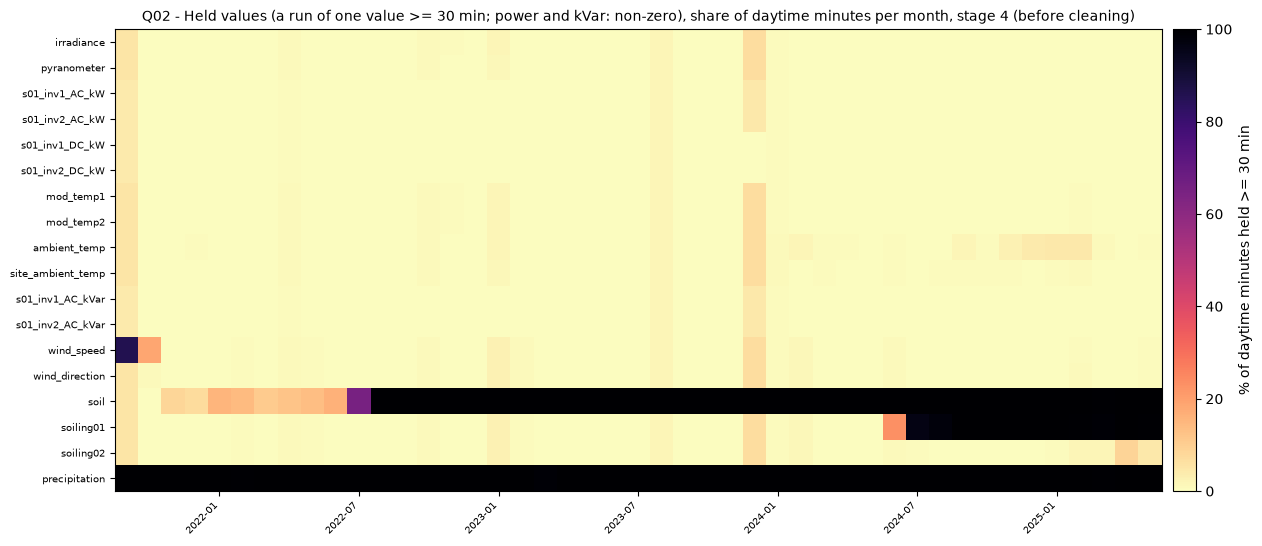

In [3]:
r = Q.q02_held_values(d)  # share of daytime minutes held >= 30 min, per tag and month
r.show()

**What it shows.** For the main sensors held values are rare
(0.62 % of train daytime minutes for irradiance,
0.40 % for inverter AC) and they appear as vertical
stripes: the same months in all tags at once — communication freezes (Q09). Three tags are dead
or partly dead: precipitation is held in all 45 months (it
never reports rain, Q30), soil is held from 2022-08
(34 months) and soiling01 from 2024-07.
Wind speed has its own stuck periods (2.7 % of daytime
minutes, worst in the first two months).

**Consequence.** Freezes of the main sensors are removed by R3; the dead tags are not used
(Q30) rather than repaired.

### Q03 — Two sampling regimes (stage-4 source detection)

**Question.** Can stage 4 tell, for every tag and hour, a one-minute average from a held 15-minute snapshot (F-18, D-21)? **Data.** Raw export, all periods: this is the detection of the export format, not a modelling choice.

class,period,minute,other,polled,tag_hours
0,before 2025-02-26,147024,1200,384,148608
1,from 2025-02-26,1257,298,10553,12108


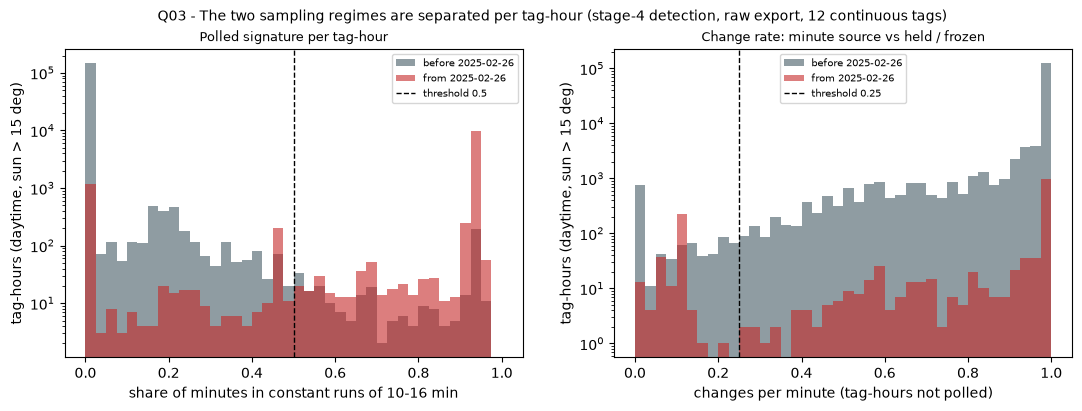

In [4]:
r = Q.q03_sampling_regime(d)  # detection statistics per tag-hour, before and after the switch
r.show()

**What it shows.** Before 2025-02-26 only 0.26 % of
tag-hours look polled (freezes and partial freezes; stage 4's era logic keeps them on the minute
source); from 2025-02-26 87.2 % are polled. Only
0.6 % of the 160,716 classified tag-hours have a poll share
between 0.3 and 0.7.

**What it means.** The two regimes are separated by a wide, almost empty gap, so the detection
thresholds of stage 4 (0.5 for the share of minutes in 10–16-minute runs, 0.25 changes per
minute) are not critical: any value inside the gap gives the same classification.

### Q04 — Value distributions before cleaning

**Question.** What do the distributions of the ranged columns look like, and where are the R1 limits? **Data.** Stage 4, all periods (descriptive; the limits are judged on train in Q05).

,column,lower,upper,minutes,n_below,n_above,min,max
0,ambient_temp,-20.0,60.0,1971172,2648,0,-270.00,48.40
1,site_ambient_temp,-20.0,60.0,1971107,0,0,0.29,48.28
2,mod_temp1,-20.0,90.0,1971133,2103,0,-270.00,68.20
3,mod_temp2,-20.0,90.0,1971095,2057,0,-270.00,67.62
4,irradiance,-20.0,1600.0,1971107,0,0,-7.84,1518.33
5,pyranometer,-20.0,1600.0,1971120,0,0,0.00,1374.22
6,wind_speed,0.0,60.0,1971107,0,46,0.00,629.24
7,s01_inv1_AC_kW,-20.0,1897.0,1971121,0,2,0.00,40825.09
8,s01_inv2_AC_kW,-20.0,1897.0,1971095,0,2,0.00,12045.41
9,s01_inv1_DC_kW,-20.0,1897.0,1971121,0,6,0.00,28150.24


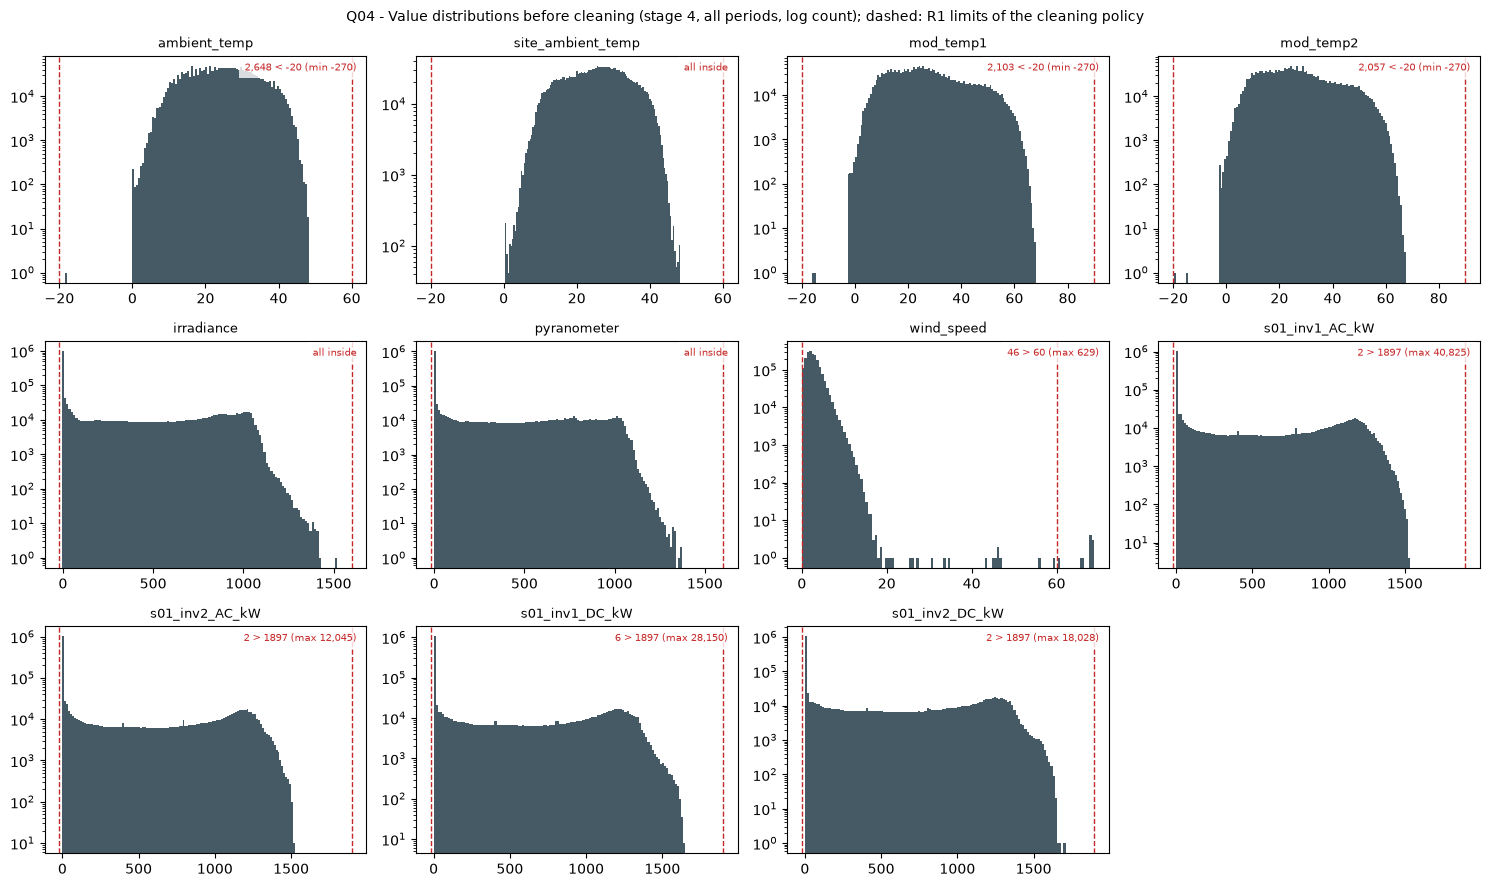

In [5]:
r = Q.q04_distributions(d)  # histograms with the R1 limits
r.show()

**What it shows.** The body of every distribution is physically plausible; the values
outside the limits form separate, isolated groups: the temperature fault code −270 °C
(2,648 minutes in ambient_temp, 2,103 and 2,057 in the
module sensors), power spikes up to 40,825 kW (2–6
minutes per power column) and wind speeds up to 629 m/s (46 minutes). Irradiance,
pyranometer and site_ambient_temp never leave their limits.

**Note.** A few isolated counts between −20 and 0 °C in the module sensors are one-minute blends
of a fault code with a real value: they are inside the limits, which is why R1 has a margin
(Q06).

## Part B — The evidence for each cleaning threshold

Each analysis below takes one rule of `configs/cleaning_policy.yaml`, looks at the stage-4 data of
the **train split**, and asks whether the threshold sits where the data say it should. Value rules
R1–R7 replace a wrong measurement (NaN or 0); flags F1–F3 mark a real plant event and never change
a value (D-22).

### Q05 — R1 — are the physical limits in empty regions?

**Question.** Is there a gap between normal values and faulty values, and does the limit sit in it? **Data.** Stage 4, train.

,column,lower,upper,train_minutes,n_below,n_above,smallest_inside,smallest_inside_not_next_to_fault,largest_inside,largest_below,smallest_above,most_frequent_outside
0,ambient_temp,-20.0,60.0,1271647,2129,0,0.03,0.03,46.57,-38.17,NaN,-270 x2107; -42 x2; -185 x2; -148 x2
1,site_ambient_temp,-20.0,60.0,1271647,0,0,0.29,0.29,45.45,NaN,NaN,
2,mod_temp1,-20.0,90.0,1271647,1732,0,-16.17,-2.50,66.21,-55.12,NaN,-270 x1712; -151 x3; -172 x1; -188 x1
3,mod_temp2,-20.0,90.0,1271647,1732,0,-19.58,-2.60,65.67,-55.57,NaN,-270 x1712; -148 x2; -66 x2; -170 x1
4,irradiance,-20.0,1600.0,1271647,0,0,-7.84,-7.84,1518.33,NaN,NaN,
5,pyranometer,-20.0,1600.0,1271647,0,0,0.00,0.00,1374.22,NaN,NaN,
6,wind_speed,0.0,60.0,1271647,0,43,0.00,0.00,59.38,NaN,60.44,70 x8; 71 x8; 73 x8; 68 x6
7,s01_inv1_AC_kW,-20.0,1897.0,1271653,0,2,0.00,0.00,1535.11,NaN,32766.26,32766 x1; 40825 x1
8,s01_inv2_AC_kW,-20.0,1897.0,1271653,0,2,0.00,0.00,1525.35,NaN,8302.36,8302 x1; 12045 x1
9,s01_inv1_DC_kW,-20.0,1897.0,1271653,0,4,0.00,0.00,1650.03,NaN,12150.37,14215 x1; 13880 x1; 26193 x1; 12150 x1


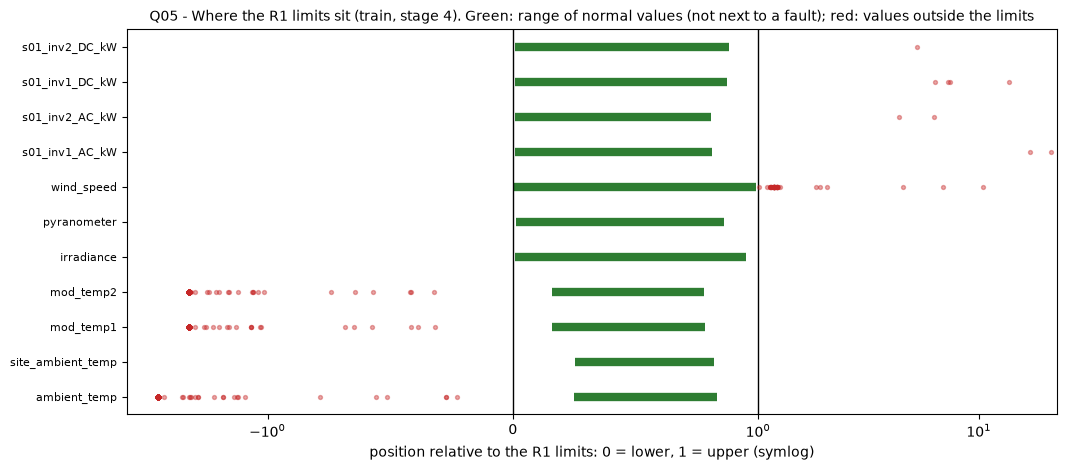

In [6]:
r = Q.q05_range_limits(d)  # normal range vs values outside the limits, per column (train)
r.show()

**What it shows.** For power, the largest normal value is
0.80–0.88 of the upper limit (1,897 kW = 1.1 × the
1,724.5 kW rating), and the smallest value above the limit is
4.4–17.3 times the
limit. For temperatures, the coldest normal readings are -2.6 °C (module, radiative
cooling on clear winter nights) and 0.03 °C (ambient) — far above −20 °C — while
the faults lie at −270 °C and blends down to -55.12 °C. Irradiance never exceeds
1,518 W/m² (cloud enhancement in the panel plane), below the
1,600 limit.

**What it means.** The limits could move a long way without changing a single decision: they are
not tuned. Two caveats: a blended minute next to a fault can lie inside the limits
(-19.58 °C in mod_temp2), which the margin handles (Q06);
and wind speed has no clean gap (values up to 59.38 m/s inside the limit are
themselves spikes), which does not matter because wind is not used (Q30).

### Q06 — R1 margin — are the neighbours of a faulty minute contaminated?

**Question.** Should the minutes next to an out-of-range value be removed too? **Data.** Stage 4, train, minute source. A neighbour is contaminated if it deviates from the next three minutes by more than the 99.9th percentile of normal one-minute changes.

,column,fault_minutes_train,neighbours_checked,normal_change_p99_9,neighbour_deviation_median,share_neighbours_beyond_normal
0,ambient_temp,2129,28,0.503,0.096,0.250
1,mod_temp1,1732,26,2.630,0.217,0.192
2,mod_temp2,1732,26,2.790,0.284,0.192
3,wind_speed,43,8,4.485,8.578,0.500
4,s01_inv1_AC_kW,2,4,646.351,5.375,0.000
5,s01_inv2_AC_kW,2,4,659.963,7.092,0.000
6,s01_inv1_DC_kW,4,8,680.185,13.220,0.000
7,s01_inv2_DC_kW,1,2,704.402,14.072,0.000


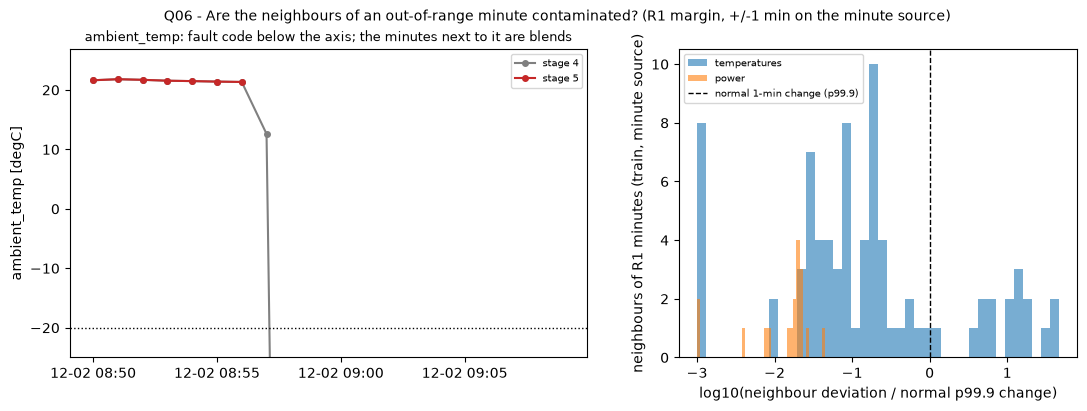

In [7]:
r = Q.q06_range_margin(d)  # neighbours of R1 minutes against normal one-minute changes (train)
r.show()

**What it shows.** Power spikes are single-minute transmission errors: none of their
neighbours is contaminated (0 %). Next to temperature
fault codes, 21.2 % of the neighbours deviate beyond
normal: a one-minute average that contains part of the fault period is a blend (left panel: a
minute at about 12 °C between 21 °C and −270 °C).

**What it means.** The ±1-minute margin on the minute source is needed for the temperature faults
and harmless for power spikes (two extra minutes per spike). On the polled source the margin is
±15 minutes by construction: stage 4 interpolates linearly between snapshots 15 minutes apart, so
one bad snapshot contaminates up to one poll period on each side.

### Q07 — R2 — negative irradiance at night

**Question.** Are negative irradiance readings an offset or a fault? **Data.** Stage 4, train, by sun elevation.

,column,sun_band,minutes,share_negative,min,p0_1,share_below_minus_20
0,irradiance,-90..-6,592886,0.05008,-7.00,-2.0,0.0
1,irradiance,-6..0,47009,0.04895,-7.84,-2.0,0.0
2,irradiance,0..10,91103,0.00009,-2.00,0.0,0.0
3,irradiance,10..90,540649,0.00000,-1.00,0.0,0.0
4,pyranometer,-90..-6,592886,0.00000,0.00,0.0,0.0
5,pyranometer,-6..0,47009,0.00000,0.00,0.0,0.0
6,pyranometer,0..10,91103,0.00000,0.00,0.0,0.0
7,pyranometer,10..90,540649,0.00000,0.00,0.0,0.0


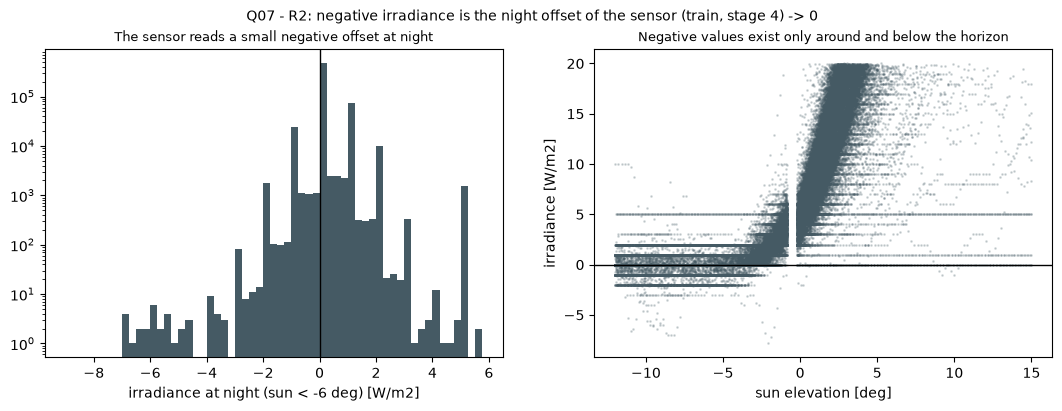

In [8]:
r = Q.q07_night_offset(d)  # negative irradiance by sun elevation (train)
r.show()

**What it shows.** 5.0 % of night minutes are
negative, the minimum is -7.84 W/m², and no value is ever below
−20 W/m². With the sun above 10° no value is negative (0 %).
The pyranometer never reads below 0 (its logger clamps at zero).

**What it means.** The negative values are the sensor's dark offset. Setting −20…0 W/m² to 0 (R2)
removes an artefact with no physical meaning and never touches daylight; R1 never sees these
values because the offset is far from −20.

### Q08 — R3 — how long does a value naturally stay constant?

**Question.** Where does natural constancy end and a freeze begin? **Data.** Stage 4, train, daytime; power: non-zero runs. The curve gives the share of daytime minutes that lie in a run of at least k identical values.

,column,R3_minimum,>=2,>=3,>=5,>=10,>=15,>=20,>=30,>=45,>=60,>=90,>=120,>=240
0,irradiance,30,1.4828,0.9564,0.7352,0.6672,0.6452,0.6390,0.6244,0.6133,0.6026,0.5902,0.5488,0.4250
1,pyranometer,30,0.7755,0.6651,0.6346,0.6133,0.5982,0.5950,0.5808,0.5697,0.5697,0.5540,0.5477,0.4245
2,s01_inv1_AC_kW,30,0.4474,0.4463,0.4407,0.4267,0.4156,0.4156,0.4014,0.3903,0.3903,0.3737,0.3737,0.2496
3,s01_inv2_AC_kW,30,0.4482,0.4467,0.4409,0.4270,0.4158,0.4158,0.4017,0.3905,0.3905,0.3739,0.3739,0.2496
4,s01_inv1_DC_kW,30,0.3225,0.3218,0.3150,0.3006,0.2893,0.2893,0.2749,0.2636,0.2636,0.2475,0.2475,0.1213
5,s01_inv2_DC_kW,30,0.3179,0.3171,0.3104,0.2964,0.2852,0.2852,0.2711,0.2599,0.2599,0.2440,0.2440,0.1197
6,mod_temp1,30,3.0417,1.6186,0.9276,0.7014,0.6405,0.6328,0.6231,0.6120,0.6013,0.5732,0.5484,0.4249
7,mod_temp2,30,3.0217,1.6068,0.9257,0.7119,0.6538,0.6411,0.6231,0.6120,0.6013,0.5730,0.5482,0.4249
8,ambient_temp,60,24.7527,15.5966,6.6159,1.6850,0.9102,0.7395,0.6283,0.6019,0.5836,0.5560,0.5495,0.4252
9,site_ambient_temp,60,2.6444,1.4951,0.9400,0.6857,0.6315,0.6255,0.5889,0.5702,0.5702,0.5545,0.5480,0.4243


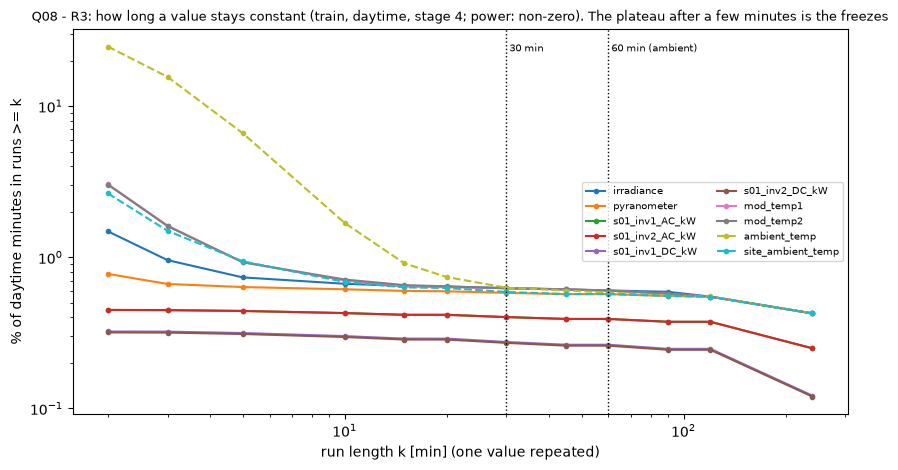

In [9]:
r = Q.q08_frozen_runs(d)  # share of daytime minutes in runs >= k (train)
r.show()

**What it shows.** Real measurements change almost every minute. The curves fall steeply
over the first minutes and then flatten: for irradiance 0.74 % of
daytime minutes lie in runs of 5 minutes or more and 0.62 % in
runs of 30 minutes or more — the plateau is the freezes. Between 15 and 60 minutes the share
changes by a factor of only 1.05–1.11 for every R3 column except
ambient_temp.

**What it means.** The 30-minute threshold sits on the plateau, so it is not sensitive. The
meteo ambient sensor has a resolution of 0.1 °C and changes slowly:
it has genuine runs of 10–30 minutes (6.6 % of minutes in runs
of 5 minutes or more) and its plateau starts later (≥ 30 / ≥ 120 min =
1.14), hence 60 minutes for the two ambient sensors. Runs of
exactly 0 kW are inverter stops (F1), not frozen sensors, and are excluded from R3.

### Q09 — R3 — sensor faults or communication freezes?

**Question.** Do long runs hit one sensor or the whole logger? **Data.** Stage 4; the share is computed on train, the event list covers all periods (descriptive).

,start_utc,end_utc,minutes,max_columns,daytime_minutes,split
0,2021-09-02 12:18:00+00:00,2021-09-02 14:45:00+00:00,147,10,147,train
1,2021-09-10 17:33:00+00:00,2021-09-11 07:09:00+00:00,816,6,177,train
2,2021-09-11 07:14:00+00:00,2021-09-12 03:13:00+00:00,1199,10,466,train
3,2021-09-27 06:12:00+00:00,2021-09-27 09:34:00+00:00,202,10,202,train
4,2021-12-19 20:54:00+00:00,2021-12-19 21:28:00+00:00,34,6,0,train
5,2022-03-07 08:41:00+00:00,2022-03-07 09:11:00+00:00,30,10,30,train
6,2022-03-08 21:24:00+00:00,2022-03-09 01:19:00+00:00,235,6,0,train
7,2022-04-16 03:00:00+00:00,2022-04-16 04:36:00+00:00,96,6,34,train
8,2022-04-19 12:39:00+00:00,2022-04-19 15:11:00+00:00,152,10,152,train
9,2022-05-02 17:58:00+00:00,2022-05-02 23:03:00+00:00,305,6,0,train


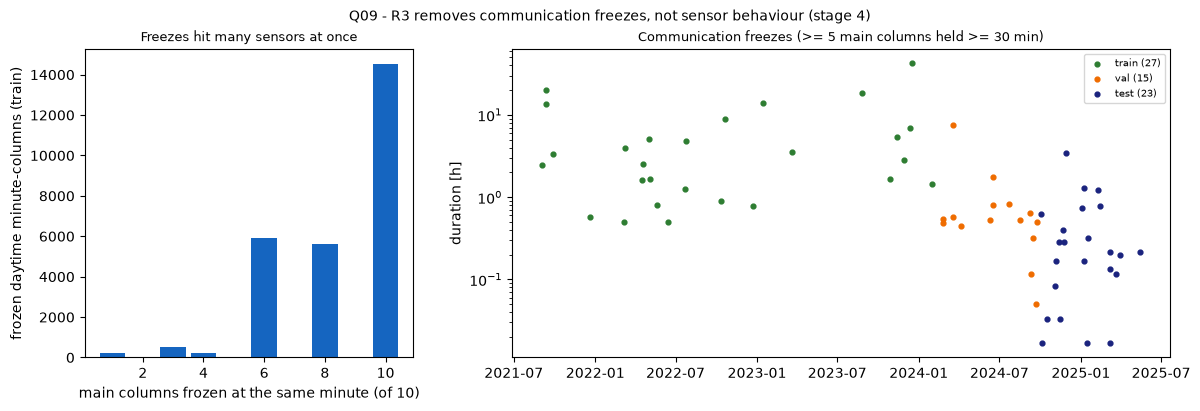

In [10]:
r = Q.q09_freeze_events(d)  # columns frozen at the same minute, and the freeze events
r.show()

**What it shows.** 96.3 % of the frozen daytime
minute-columns in train have at least five of the ten main columns frozen at the same minute.
There are 65 freeze events in the whole period (27
train, 15 val, 23 test),
17 of which reach daylight; the longest lasts
42 hours (2021-09-10/12).

**What it means.** Long constant runs are communication freezes: the historian repeats stale
values of every tag. R3 therefore removes copies of old values, not measurements.

### Q10 — R3 margin — what happens when data resume?

**Question.** Is the first minute after a freeze a real measurement? **Data.** Stage 4, minute source; resumes with a clear jump. Position 0 = the stale value, 1 = the next minute's value.

,column,resume_utc,split,stale,first_new,next,position
0,irradiance,2021-09-02 14:45:00+00:00,train,757.00,488.34,182.07,0.467
1,irradiance,2021-09-11 07:10:00+00:00,train,0.00,749.10,594.73,1.260
2,irradiance,2021-09-12 03:13:00+00:00,train,1006.00,378.66,1.00,0.624
3,irradiance,2021-09-27 09:34:00+00:00,train,579.00,653.60,1008.45,0.174
4,irradiance,2022-04-16 04:36:00+00:00,train,1.00,54.94,214.10,0.253
5,irradiance,2022-04-19 15:11:00+00:00,train,653.00,524.66,104.31,0.234
6,irradiance,2022-09-06 09:48:00+00:00,train,0.00,950.17,997.74,0.952
7,irradiance,2022-10-20 07:55:00+00:00,train,0.00,663.95,845.85,0.785
8,irradiance,2022-11-01 12:23:00+00:00,train,0.00,252.45,563.89,0.448
9,irradiance,2023-01-14 09:27:00+00:00,train,0.00,622.09,912.66,0.682


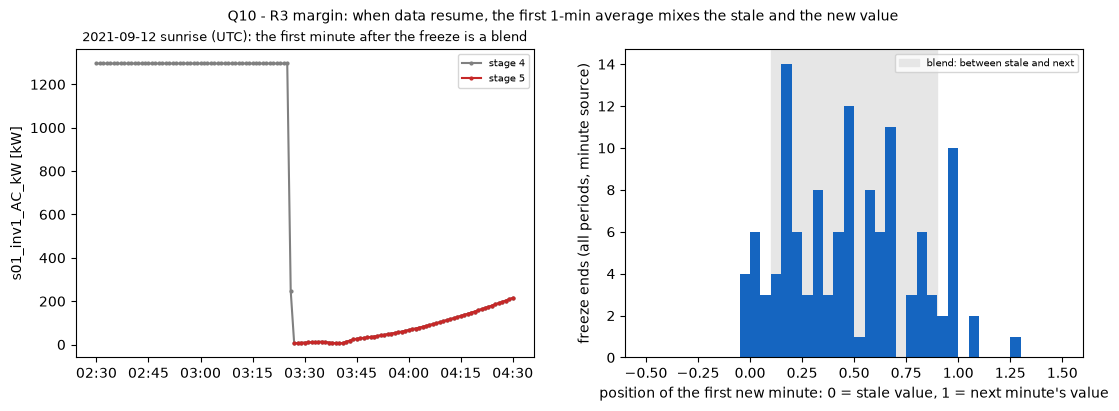

In [11]:
r = Q.q10_freeze_resume(d)  # position of the first minute after each freeze
r.show()

**What it shows.** In 77.8 % of the 108 train
resumes the first new value lies between the stale value and the next minute — a blend. Example:
247 kW at sunrise on 2021-09-12 after a night frozen at 1,296 kW (left
panel; found in stage 3).

**What it means.** The resume minute is neither the old nor the new truth, so R3 removes one
minute on each side of a frozen run on the minute source and one poll period (15 minutes) on the
polled source, where the reconstruction interpolates from the stale snapshot.

### Q11 — R4 and R5 — what is real at night and in twilight?

**Question.** Which readings below the horizon are noise, stale values or production? **Data.** Stage 4, train, by sun elevation; frozen = in or within 15 minutes of a run of at least 30 minutes.

,column,sun_band,minutes,share_zero,share_0_to_5kW,share_above_5kW,p99_9_not_frozen,max_not_frozen,max_any
0,s01_inv1_AC_kW,-90..-6,592892,0.9953,0.0000,0.0047,0.00,0.00,1296.1
1,s01_inv1_AC_kW,-6..-3,25955,0.9950,0.0005,0.0045,0.00,3.61,1296.1
2,s01_inv1_AC_kW,-3..0,21054,0.7881,0.1416,0.0703,12.28,28.82,1296.1
3,s01_inv1_AC_kW,0..5,46776,0.0820,0.0620,0.8561,94.18,134.22,1296.1
4,s01_inv1_AC_kW,5..10,44327,0.0064,0.0008,0.9928,267.36,344.30,1296.1
5,s01_inv2_AC_kW,-90..-6,592892,0.9953,0.0000,0.0047,0.00,0.00,1290.6
6,s01_inv2_AC_kW,-6..-3,25955,0.9948,0.0007,0.0045,0.00,4.88,1290.6
7,s01_inv2_AC_kW,-3..0,21054,0.7571,0.1167,0.1262,14.73,29.42,1290.6
8,s01_inv2_AC_kW,0..5,46776,0.0940,0.0293,0.8767,104.45,136.54,1290.6
9,s01_inv2_AC_kW,5..10,44327,0.0070,0.0003,0.9928,279.35,350.93,1290.6


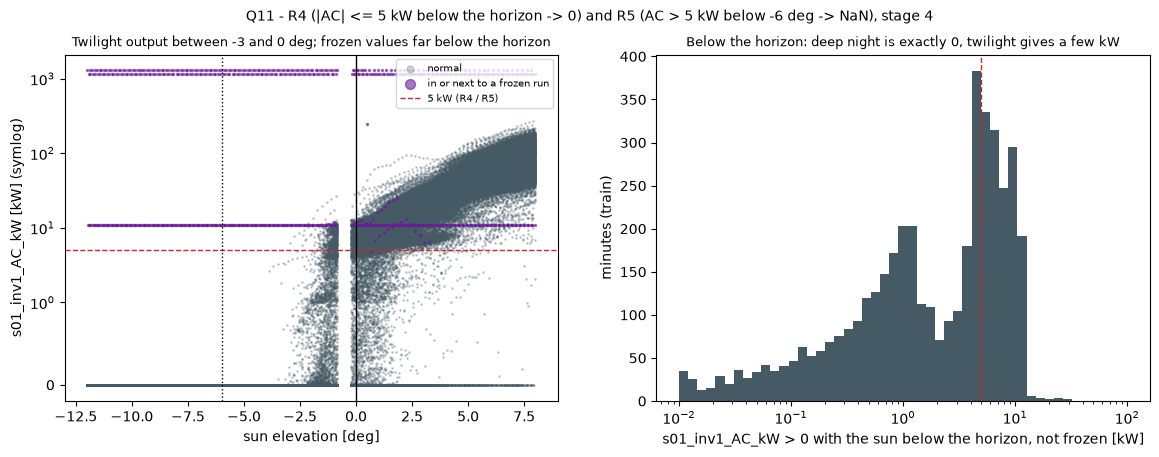

In [12]:
r = Q.q11_night(d)  # inverter AC by sun elevation (train)
r.show()

**What it shows.** Far below the horizon (sun below −6°) the inverters read exactly 0
whenever the data are live (0 non-zero minutes
outside freezes): there is no night noise. Every reading above 5 kW below −6°
(5,616 minutes, all periods) is in or next to a frozen run
(100 %). Between −3° and 0° the plant produces a little —
up to 29 kW (diffuse light at dusk and dawn).

**What it means.** R5 (power above 5 kW with the sun below −6° → NaN) removes only stale values.
R4 (|power| ≤ 5 kW below the horizon → 0) was described as removing night noise, but the data show
none: 94 % of its candidates are twilight readings
between −3° and 0°, i.e. tiny real production. Its effect is negligible
(238 kWh in 3¾ years, about 0.001 % of the energy) and it falls where k is
undefined and no evaluation takes place, so R4 is kept to make the target exactly 0 when the sun
is down; its justification is corrected in the policy and the record.

### Q12 — R6 — dead DC sensor, and the consistency of DC with AC

**Question.** Is DC consistent with AC, and what does R6 remove? **Data.** Stage 4, train daytime for the efficiency; R6 minutes over all periods (descriptive).

,inverter,minutes_dc_over_300,efficiency_p1,efficiency_median,efficiency_p99,share_ac_above_dc,share_ac_above_dc_stable,median_efficiency_stable,r6_minutes_all,r6_top_month,r6_share_top_month
0,inv1,459956,0.8310,0.9721,0.9970,0.0072,0.0005,0.9700,7056,2023-03,0.9974
1,inv2,466222,0.8065,0.9709,0.9982,0.0080,0.0006,0.9684,46,2025-02,0.6739


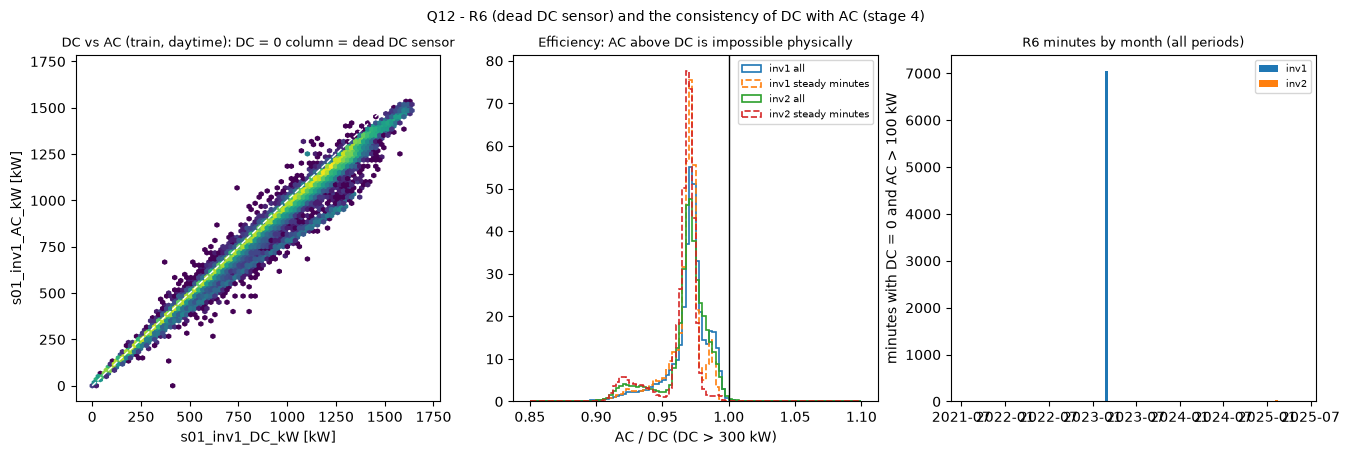

In [13]:
r = Q.q12_dc_consistency(d)  # AC/DC efficiency and the dead-DC minutes
r.show()

**What it shows.** The median conversion efficiency is 97.2 %
(inverter 1) and 97.1 % (inverter 2). AC above DC — physically
impossible — appears in 0.7 % of minutes, but in only
0.05 % of steady minutes: it is a timing effect of two
one-minute averages during fast ramps, not a sensor fault. R6 (DC = 0 while AC > 100 kW) hits
7,056 minutes of inverter 1, 99.7 % of
them in 2023-03, and 46 minutes of inverter 2.

**What it means.** One dead DC sensor in March 2023; DC needs no other rule. DC is not a model
input, so R6 matters for QA and the clock check only. The lower band in the left panel
(AC ≈ 0.78 × DC) is the derated inverter of Q16.

### Q13 — R7 — the pyranometer's scale fault

**Question.** Is the redundant pyranometer consistent with the irradiance sensor, and how should a fault be detected? **Data.** Stage 4 pyranometer against the cleaned irradiance; bright minutes only (sun > 30°, irradiance > 300 W/m²); train for the thresholds.

,local_day,split,usable_minutes,median_ratio,day_rule
0,2021-09-01,train,479,0.9980,False
1,2021-09-02,train,396,0.9945,False
2,2021-09-03,train,476,0.9967,False
3,2021-09-04,train,475,0.9981,False
4,2021-09-05,train,473,0.9984,False
5,2021-09-06,train,471,0.9980,False
6,2021-09-07,train,469,0.9985,False
7,2021-09-08,train,467,1.0011,False
8,2021-09-09,train,466,1.0020,False
9,2021-09-10,train,463,1.0046,False


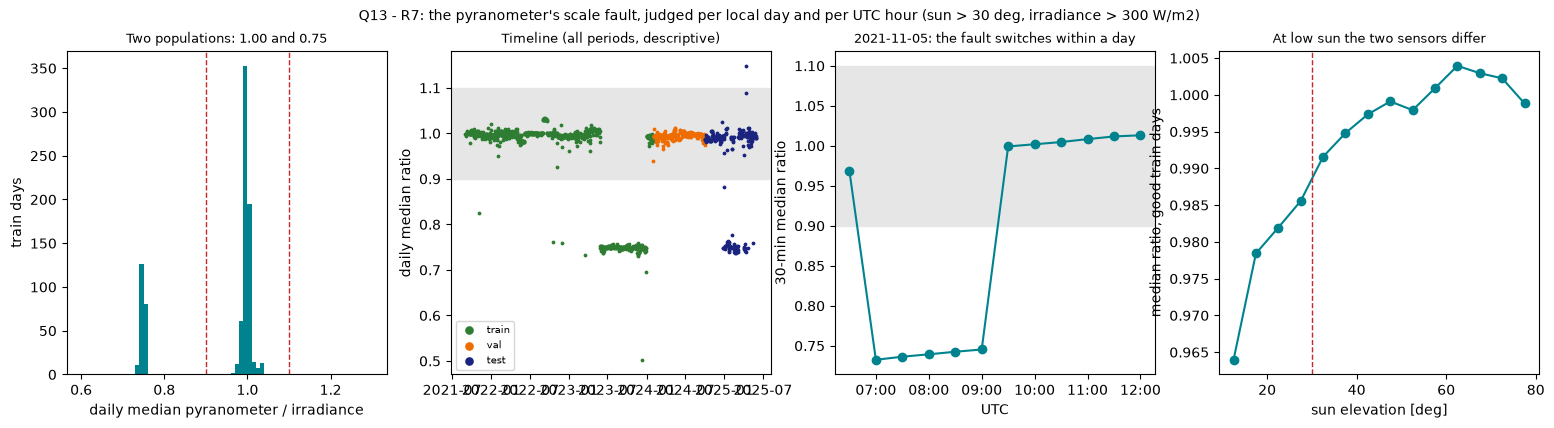

In [14]:
r = Q.q13_scale_fault(d)  # daily and hourly ratio pyranometer / irradiance
r.show()

**What it shows.** Per local day the ratio forms two populations in train:
0.998 (inter-quartile range 0.994–1.001)
and 0.749 — a calibration constant switched to exactly ×0.75 on
221 train days (and 60 test days). The band
0.9–1.1 lies in the empty space between them. The only train day inside the gap, 2021-11-05
(ratio 0.83), is a day on which the fault switched on and off (third panel: ×0.75
from 07:00 to 09:00 UTC, ×1.00 afterwards).

**What it means.** A daily median misses faults that cover part of a day, so R7 now also judges
every UTC hour (finding F-21); in train this adds 28 hours
(6 of them at ≈ 0.75, the others hours where the two sensors
disagree by more than 10 % for other reasons). A period is judged only with enough usable minutes
(at least 20): a freeze day had been decided on 2 minutes. The sun must be above
30° because at low sun the two sensors differ by a few percent through their angular (cosine)
response (fourth panel). The pyranometer is not a model input; the irradiance sensor that the
models use was verified against clear-sky irradiance in stage 3 (F-19).

### Q14 — F1 — what does an inverter stop look like?

**Question.** Is 20 kW the right line between a stop and low production? **Data.** Train, after the value rules; sun above 5° and irradiance above 150 W/m².

,column,minutes,share_below_20kW,share_20_to_100kW,median_ac_at_150_200_wm2,p1_ac_at_150_200_wm2
0,s01_inv1_AC_kW,505463,0.00369,0.00027,216.9,132.1
1,s01_inv2_AC_kW,505463,0.00422,0.00027,222.4,140.4


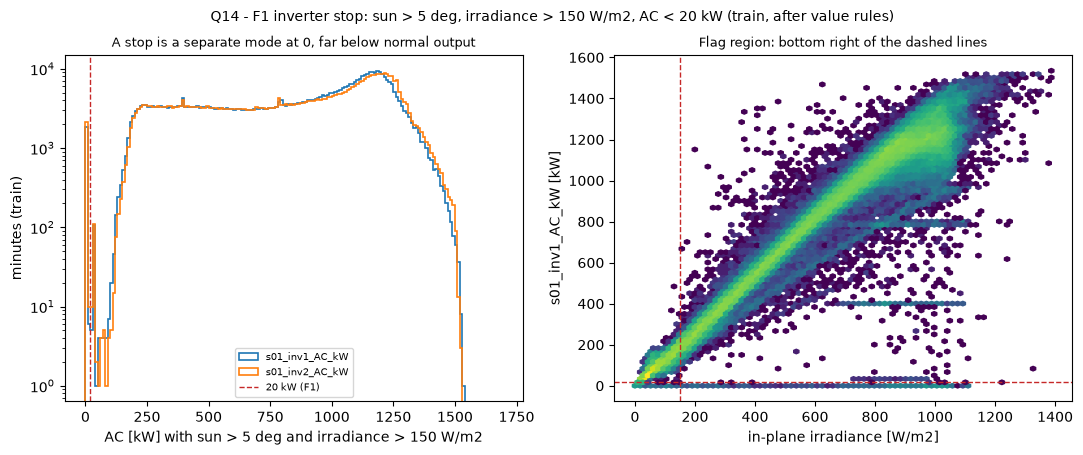

In [15]:
r = Q.q14_downtime(d)  # inverter AC when the sun is up and bright (train)
r.show()

**What it shows.** Even at the lowest irradiance of the rule (150–200 W/m²) an inverter
normally produces about 217 kW (1st percentile
132 kW). Stops form a separate mode below 20 kW
(0.37 % and 0.42 %
of these minutes), and the region between 20 and 100 kW is almost empty
(0.027 %).

**What it means.** The 20 kW threshold sits in a valley far below normal output; F1 marks stops
without changing any value (D-22).

### Q15 — F2 — does the setpoint really limit output?

**Question.** Does a park setpoint below 100 % limit our two inverters, and does `iec_mode`? **Data.** Stage 4, train. Relative output = AC per unit irradiance over its median in the same calendar month in normal operation (1.0 = normal).

,day,split,minutes,median_setpoint,integer_share,flagged_share,relative_output
0,2022-02-09,train,167,98.559,0.000,0.000,1.029
1,2022-02-10,train,606,77.290,0.000,0.000,1.087
2,2022-02-11,train,607,52.208,0.000,0.000,1.001
3,2022-02-12,train,456,28.501,0.057,0.061,0.994
4,2022-12-22,train,127,50.000,0.969,1.000,0.683
5,2023-02-17,train,93,50.000,0.957,1.000,0.582
6,2023-02-18,train,252,25.000,0.937,1.000,0.279
7,2023-03-16,train,176,50.000,0.972,1.000,0.547
8,2023-03-18,train,248,50.000,0.935,1.000,0.623
9,2023-04-06,train,217,25.000,0.945,1.000,0.333


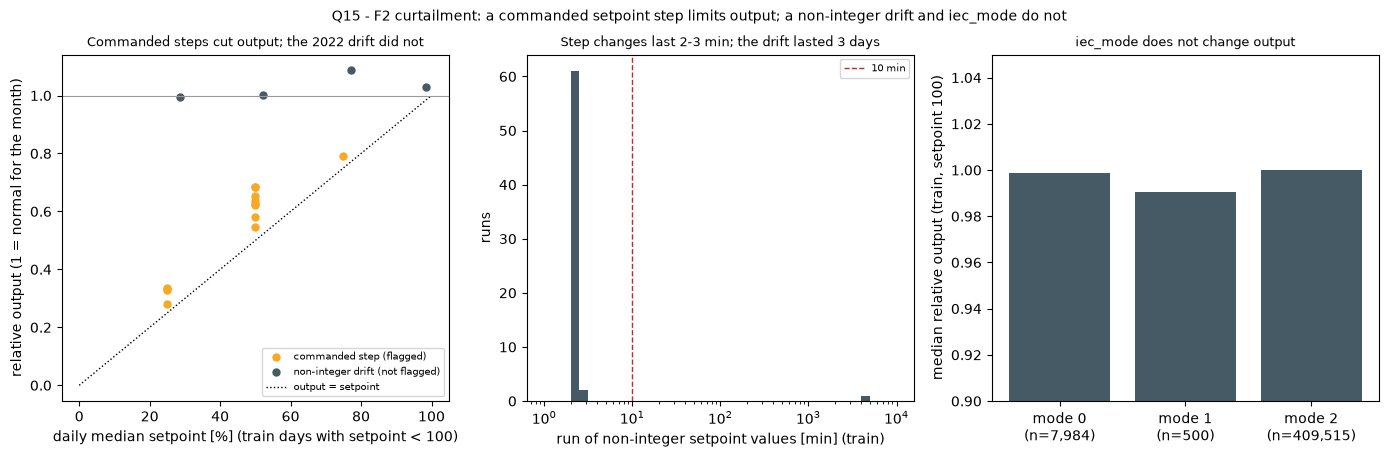

In [16]:
r = Q.q15_curtailment(d)  # output under each setpoint, setpoint runs, and iec_mode (train)
r.show()

**What it shows.** Under a commanded step the output falls to 0.03 (setpoint
0 %), 0.33 (25 %), 0.64 (50 %) and 0.84 (75 %) of normal —
roughly the setpoint plus ten points (the setpoint applies to the whole 40 MW park, not exactly
to our segment). On 2022-02-09…12, however, the setpoint drifted through non-integer values from
98 % to 28 % for 4,309 minutes while output stayed normal
(0.99–1.09). A real step shows at most
3 non-integer minutes (the minute that contains the step is a
blend).

**What it means.** The drift was not a command. F2 now ignores runs of non-integer setpoint values
longer than 10 minutes (finding F-20): this removes 1,808 wrongly flagged train minutes and
leaves validation and test unchanged. `iec_mode` does not change output (modes 0/1/2:
0.999/0.990/1.000),
which confirms F-17: it is not used.

### Q16 — F3 — a derated inverter (new flag)

**Question.** Are there periods in which one inverter produces only part of its normal output, unseen by F1? **Data.** Stage 5 AC (after the value rules), train; the ratio AC1/AC2 in a centred 31-minute window, with the sun above 15° and both inverters above 100 kW.

,inverter,state,episode,minutes,median_ratio_to_other
0,inv1,1,all,468029,0.989
1,inv1,3,all,1274,1.008
2,inv1,5,run >= 30 min,3994,0.739
3,inv1,5,run < 30 min,604,0.715
4,inv2,1,all,466044,1.012
5,inv2,3,all,3188,0.770
6,inv2,5,run >= 30 min,3961,0.768
7,inv2,5,run < 30 min,191,0.766
8,inv2,6,run >= 30 min,672,0.765


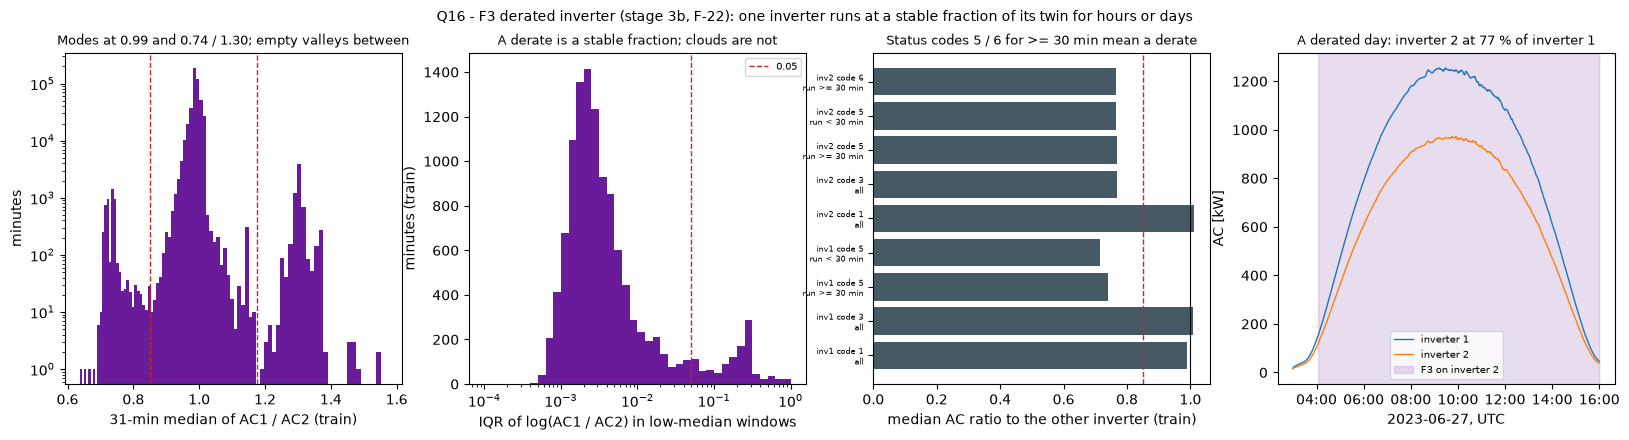

In [17]:
r = Q.q16_derate(d)  # windowed inverter ratio, its stability, and the status codes (train)
r.show()

**What it shows.** The windowed ratio has its main mode at 0.99
and secondary modes at 0.74 and 1.30 (inverter 1
or inverter 2 derated, for hours or whole days); only
0.17 % of the windows lie in the valleys where the thresholds 0.85
and 1/0.85 sit. A derate is a stable fraction: 82 % of the
low windows have an inter-quartile range of the log ratio below 0.01, while clouds over one field
and the 2025 polling phases give 0.1–0.5 (9 % of low windows,
not flagged). The status codes agree: in code 1 the ratio is 0.99 /
1.01; in codes 5 and 6 sustained for 30 minutes or more it is
0.74 / 0.77. Short start-up
episodes of code 5 are not flagged; code 3 is ambiguous (derated on inverter 2,
0.77; normal on inverter 1, 1.01), so it is left
to the ratio rule.

**What it means.** A partial outage is an operational limitation like a stop or curtailment, so it
gets a flag (finding F-22, flag F3; values unchanged, D-22): 245 train,
43 validation and 93 test daytime hours, with
about 42 / 9 /
17 MWh not produced. Without it, the models would learn these
hours as weather.

### Q17 — Hourly thresholds — coverage 45/60 and op-limited share 0.05

**Question.** Are the two hourly thresholds sensitive? **Data.** Train daytime hours (evaluation mask).

,threshold,daytime_train_hours_affected
0,coverage >= 30/60,39
1,coverage >= 40/60,41
2,coverage >= 45/60,42
3,coverage >= 50/60,44
4,coverage >= 55/60,44
5,coverage >= 60/60,49
6,op-limited share >= 0.01,382
7,op-limited share >= 0.02,381
8,op-limited share >= 0.05,379
9,op-limited share >= 0.1,375


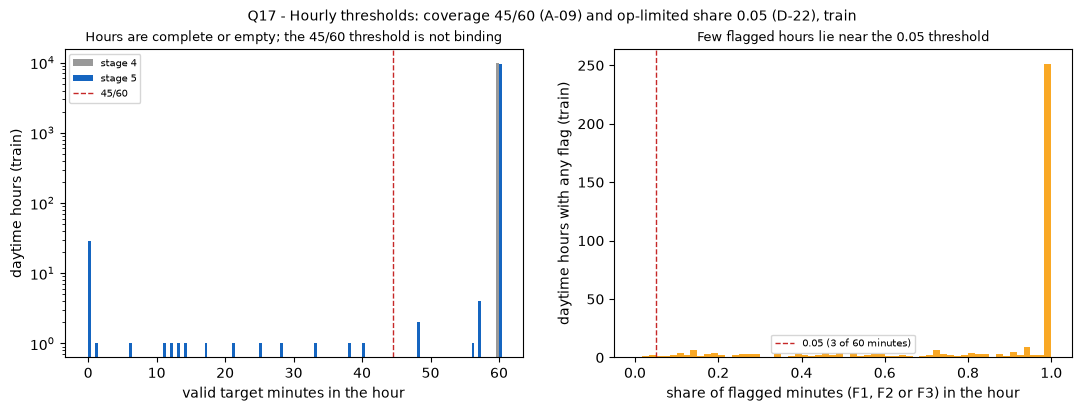

In [18]:
r = Q.q17_hourly_thresholds(d)  # valid minutes per hour and flagged share per hour (train)
r.show()

**What it shows.** Hours are either complete or empty: of 9,698
train daytime hours, 13 have between 1 and 44 valid target
minutes and 29 have none. Flagged hours are mostly fully flagged
(67 %), and the number of op-limited hours hardly depends on
the share threshold: 382 at 0.01, 379 at 0.05 and 375 at 0.10.

**What it means.** Neither the coverage threshold (A-09) nor the op-limited share (D-22) is a
sensitive choice; any reasonable value gives the same hours.

## Part C — What cleaning changed (stage 5 against stage 4)

Descriptive analyses over the whole period: what each rule changed, whether the body of the data
stayed intact, whether energy is conserved, what is missing, and whether anything is left.

### Q18 — What each rule changed, where and when

**Question.** How much did each rule change, in which split and in which months? **Data.** Rule codes of stage 5, all periods.

,rule,column,split,minutes,pct_of_split_minutes,daytime_minutes,kwh_changed
0,R1_range,ambient_temp,train,2157,0.1696,171,NaN
1,R1_range,ambient_temp,val,238,0.0680,0,NaN
2,R1_range,ambient_temp,test,303,0.0866,164,NaN
3,R3_frozen,ambient_temp,train,7624,0.5995,3110,NaN
4,R3_frozen,ambient_temp,val,75,0.0214,75,NaN
5,R3_frozen,ambient_temp,test,124,0.0355,124,NaN
6,R2_offset,irradiance,train,32000,2.5163,2,NaN
7,R2_offset,irradiance,val,17188,4.9120,0,NaN
8,R2_offset,irradiance,test,8550,2.4447,0,NaN
9,R3_frozen,irradiance,train,8743,0.6875,3405,NaN


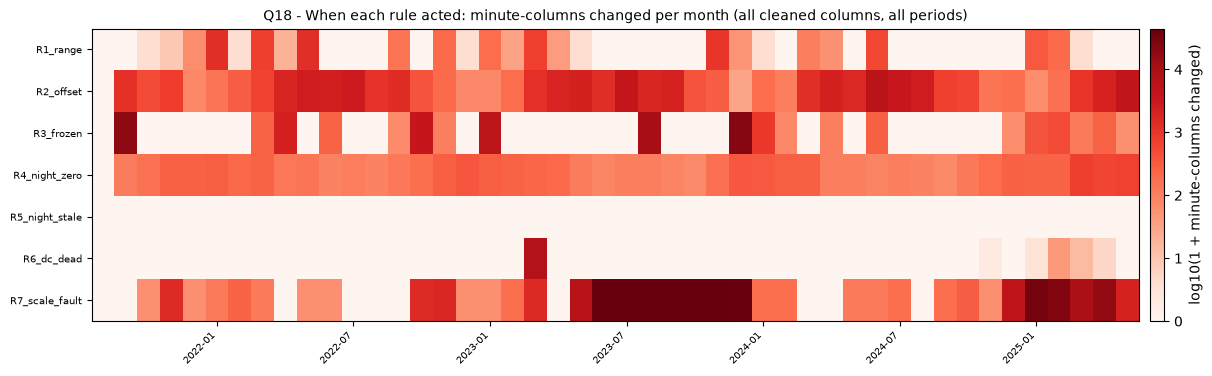

In [19]:
r = Q.q18_changes(d)  # minutes and energy changed by rule, column and split
r.show()

**What it shows.** The counts equal the cleaning log (yes).
In minutes, R7 dominates (409,160 pyranometer minutes: whole
faulty days and hours), followed by R3 (66,436) and the R2 night
offset (57,738); R1, R4 and R6 are small. Of the 557,092
changed minute-columns, 432,217 are in train, where the 2023
pyranometer fault and most freezes fall. Each rule acts in a few months (heatmap): R6 in
2023-03, R7 mostly in 2023.

**Energy.** Cleaning removed 121 MWh of inverter AC under
R3 and 1.7 MWh under R1 — stale values held through
freezes (e.g. 1,296 kW repeated through a night) and spikes, not production.

### Q19 — Did the distributions change only in the tails?

**Question.** Did cleaning change the body of the data? **Data.** Daytime values of every cleaned column, all periods; shift of the 1st, 50th and 99th percentiles as a share of the 1–99 % range.

,column,daytime_minutes_before,daytime_minutes_after,min_before,min_after,max_before,max_after,p0.1_before,p0.1_after,p0.1_shift_pct,p1_before,p1_after,p1_shift_pct,p50_before,p50_after,p50_shift_pct,p99_before,p99_after,p99_shift_pct,p99.9_before,p99.9_after,p99.9_shift_pct
0,ambient_temp,846454,842810,-270.00,3.68,48.40,48.40,7.72,8.44,2.267,11.82,12.00,0.562,28.70,28.70,0.000,43.56,43.57,0.035,45.70,45.70,0.000
1,irradiance,846389,842734,-1.00,0.00,1518.33,1518.33,0.00,26.14,2.513,50.00,53.40,0.327,674.25,675.06,0.078,1090.00,1090.14,0.013,1193.02,1193.33,0.030
2,mod_temp1,846415,842675,-270.00,3.60,68.20,68.20,7.66,9.04,2.921,13.40,13.54,0.297,39.01,39.04,0.072,60.51,60.52,0.024,63.87,63.88,0.029
3,mod_temp2,846377,842673,-270.00,3.60,67.62,67.62,7.44,8.70,2.725,12.90,13.08,0.393,38.04,38.08,0.071,59.30,59.30,0.009,62.84,62.84,0.009
4,pyranometer,846402,664205,0.00,5.06,1374.22,1374.22,1.33,23.68,2.180,54.50,63.58,0.886,621.75,673.52,5.050,1079.59,1086.42,0.666,1149.18,1157.36,0.798
5,s01_inv1_AC_kW,846402,844040,0.00,0.00,40825.09,1535.11,0.00,0.00,0.000,32.08,32.74,0.050,881.14,880.90,0.018,1365.25,1365.38,0.010,1454.64,1454.66,0.001
6,s01_inv1_DC_kW,846402,837982,0.00,0.00,28150.24,1650.03,0.00,0.00,0.000,0.00,20.80,1.448,905.03,910.08,0.352,1436.94,1437.50,0.039,1568.48,1568.57,0.006
7,s01_inv2_AC_kW,846376,844065,0.00,0.00,12045.41,1525.35,0.00,0.00,0.000,31.92,32.37,0.033,888.96,888.66,0.022,1389.00,1389.07,0.005,1470.21,1470.23,0.002
8,s01_inv2_DC_kW,846376,844721,0.00,0.00,18027.69,1710.01,0.00,0.00,0.000,18.52,18.51,0.001,921.28,920.41,0.060,1474.04,1474.21,0.012,1582.60,1582.57,0.002
9,site_ambient_temp,846441,843339,3.69,3.69,48.28,48.28,8.42,8.41,0.040,12.18,12.23,0.174,29.85,29.86,0.046,43.10,43.10,0.009,45.47,45.48,0.025


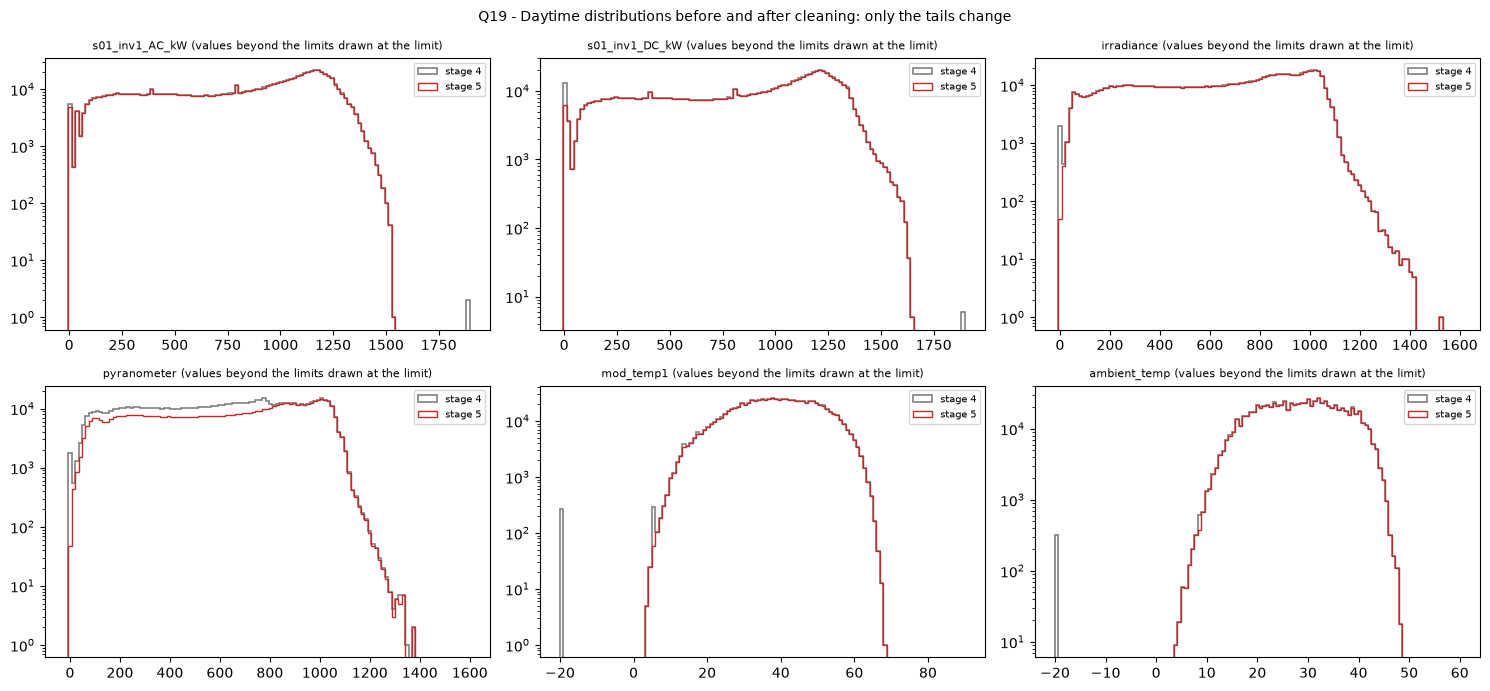

In [20]:
r = Q.q19_distributions(d)  # quantiles before and after cleaning
r.show()

**What it shows.** For the model-relevant columns the percentiles move by at most
0.56 % of their range, and after cleaning no
value lies outside the policy limits (0 minutes). Two QA
columns shift more, by design: the pyranometer (5.0 %,
whole ×0.75 days removed by R7) and DC of inverter 1
(1.4 %, the dead-sensor zeros removed by R6).

**What it means.** Cleaning changes the tails, not the body of the data. (The plan expected less
than 1 % for every column; the two exceptions are explained by rules that remove whole faulty
populations.)

### Q20 — Is energy conserved?

**Question.** Does cleaning change daily energy? **Data.** Daily site energy (local days) before and after, all periods.

,local_day,split,mwh_before,mwh_after,change_pct,main_rule
0,2021-09-02,train,21.013,16.028,-23.72,R3_frozen
1,2021-09-11,train,34.702,0.110,-99.68,R3_frozen
2,2021-09-12,train,36.731,20.056,-45.40,R3_frozen
3,2021-09-27,train,15.938,10.716,-32.76,R3_frozen
4,2022-02-28,train,19.418,19.243,-0.90,R1_range
5,2022-03-07,train,18.239,16.886,-7.42,R3_frozen
6,2022-04-19,train,19.346,14.661,-24.22,R3_frozen
7,2022-06-13,train,19.600,18.510,-5.56,R3_frozen
8,2022-12-14,train,12.215,11.583,-5.17,R1_range
9,2023-02-18,train,11.617,11.383,-2.01,R1_range


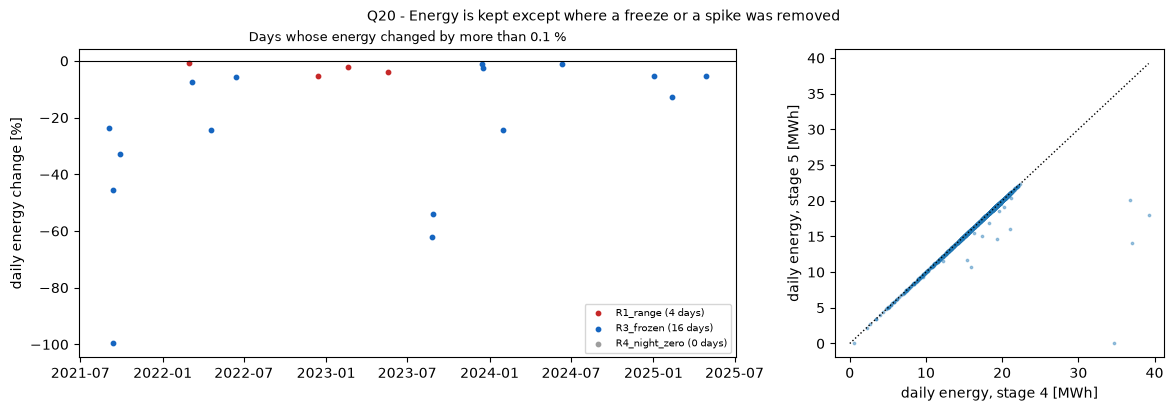

In [21]:
r = Q.q20_energy(d)  # daily energy before and after cleaning
r.show()

**What it shows.** Daily energy is unchanged on 1,349 of
1,369 days. The 20 days that change by more than 0.1 % are all freeze
(16) or spike (4) days; the largest change
(-99.7 %, 2021-09-11) is a day whose recorded energy was almost entirely
a frozen value. Over the splits the change is -0.81 %
(train), -0.006 % (validation) and
-0.11 % (test).

**What it means.** Cleaning never removes real production (T-16, T-27). The plan expected less
than 0.5 % in every split; train exceeds it only because two long freezes (2021-09-11/12 and
2023-08-26/27) held high values for many hours — energy that was never produced.

### Q21 — Where is data missing after cleaning?

**Question.** What is missing after cleaning, and where? **Data.** Stage 5, daytime minutes and hours, all periods.

,split,daytime_hours,target_nan_daytime_hours,pct,longest_gap_hours
0,train,9698,42,0.433,9
1,val,2902,1,0.034,1
2,test,2580,5,0.194,2


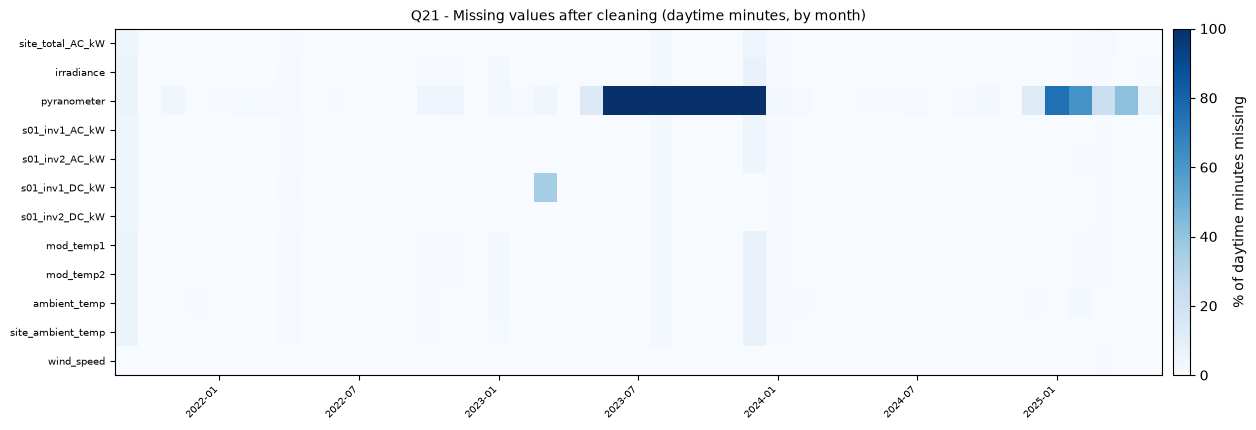

In [22]:
r = Q.q21_missing_after(d)  # missing values by column and month; target gaps by split
r.show()

**What it shows.** 0.31 % of daytime target minutes are missing —
42 / 1 /
5 daytime hours in train / validation / test, all from
communication freezes. The model inputs miss 0.44–0.46 %
of daytime minutes; the pyranometer 21.5 % (R7) and DC of inverter 1
1.0 % (R6), both QA columns.

**What it means.** Missing hours stay NaN. How past-day features see them is decided by the
imputation policy of stage 6 (expanding median and forward fill; never backward fill).

### Q22 — Is anything left?

**Question.** After cleaning, are there remaining frozen runs, impossible values or unexplained outliers? **Data.** Stage 5, all periods (descriptive; a finding would go back to stage 5).

,check,timestamp_utc,value,split
0,hourly AC / clear-sky AC > 1.2,2021-09-05 15:00:00+00:00,1.260,train
1,hourly AC / clear-sky AC > 1.2,2021-10-23 14:00:00+00:00,1.202,train
2,hourly AC / clear-sky AC > 1.2,2021-10-24 14:00:00+00:00,1.224,train
3,hourly AC / clear-sky AC > 1.2,2022-01-15 14:00:00+00:00,1.335,train
4,hourly AC / clear-sky AC > 1.2,2022-03-30 15:00:00+00:00,1.397,train
5,hourly AC / clear-sky AC > 1.2,2022-04-04 15:00:00+00:00,1.244,train
6,hourly AC / clear-sky AC > 1.2,2022-04-09 15:00:00+00:00,1.226,train
7,hourly AC / clear-sky AC > 1.2,2022-04-13 15:00:00+00:00,1.418,train
8,hourly AC / clear-sky AC > 1.2,2022-04-16 15:00:00+00:00,1.233,train
9,hourly AC / clear-sky AC > 1.2,2022-04-22 15:00:00+00:00,1.542,train


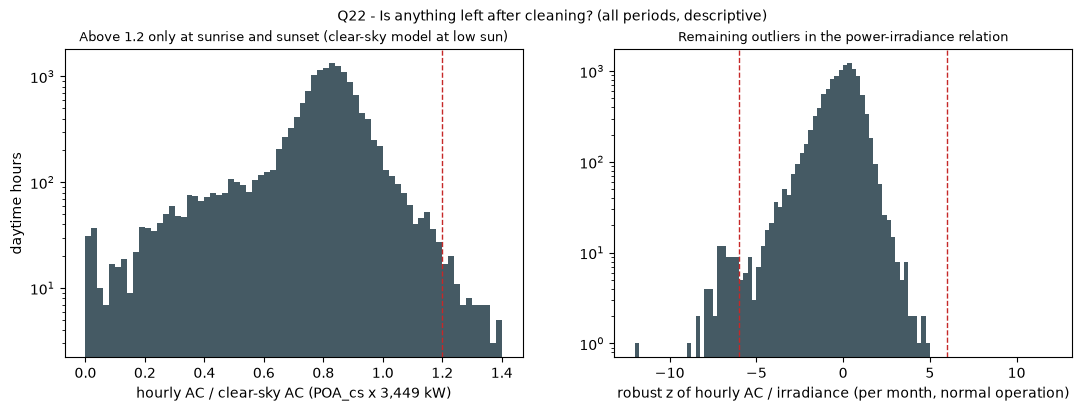

In [23]:
r = Q.q22_residual(d)  # residual checks on the cleaned data
r.show()

**What it shows.** No frozen daytime run of 30 minutes or more is left in any main column
(0 minutes). 109 daytime hours
have AC above 1.2 × the clear-sky AC; 98 % of them have the
sun below 15° (03 and 14–15 UTC). 65 hours are robust outliers of AC per unit
irradiance; 64 of them are at 05 UTC in December and
January. Without flag F3, 268 daytime hours would show an inverter
imbalance (ratio outside 0.8–1.25); with it, 22 remain.

**What it means.** None of these is a data error. At sunrise and sunset the isotropic clear-sky
model underestimates the light on the panels, so the clear-sky index is unstable at low sun —
relevant to the denominator of k and its theo > 50 kW rule (D-11, stage 6). On winter mornings
the rows of panels shade each other while the irradiance sensor is not shaded — a physical effect
the models must learn from sun elevation and azimuth. The few remaining imbalance hours are
short or cloudy episodes below the F3 thresholds.

## Part D — The cleaned data for modelling

Properties of the cleaned data that bear on the next stages. Anything that could inform a modelling
choice is computed on train only.

### Q23 — The real ceiling of each inverter

**Question.** How close does the plant come to the assumed capacity of 3,449 kW (A-08)? **Data.** Stage 5, train.

,inverter,ac_p99_99,ac_max,dc_max,minutes_ac_above_1500,days_max_above_1500,median_ac_at_dc_1600_1650,rating_assumed_kw
0,inv1,1508.5,1535.1,1650.0,104,16,1480.3,1724.5
1,inv2,1503.6,1525.3,1672.3,106,17,1483.9,1724.5


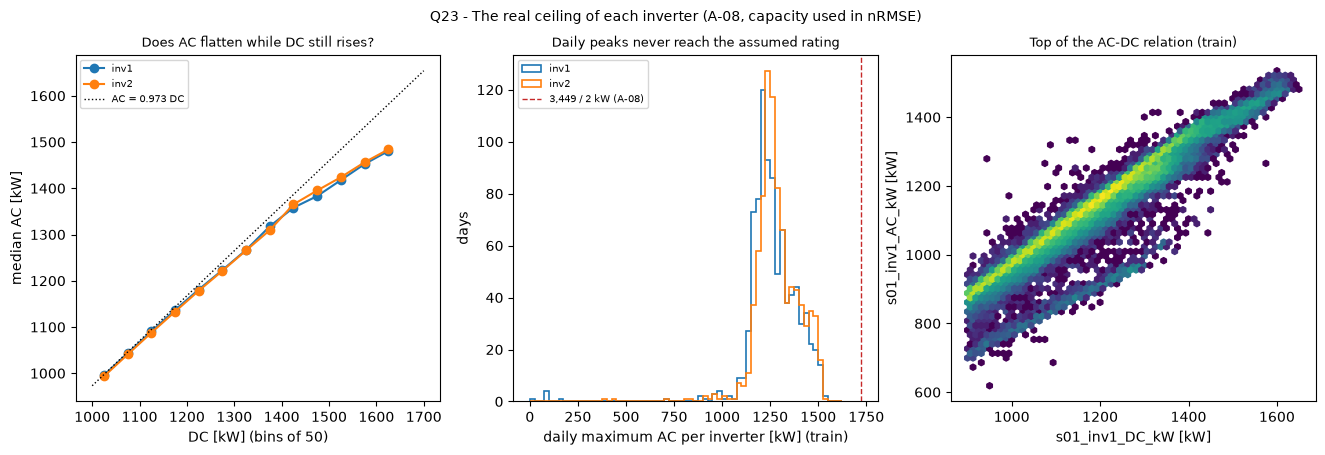

In [24]:
r = Q.q23_inverter_ceiling(d)  # AC against DC at the top, and daily peaks (train)
r.show()

**What it shows.** Neither inverter approaches the assumed rating of 1,724.5 kW: the
maximum is 1,535 / 1,525 kW (99.99th percentile
1,508 / 1,504 kW), and the highest hourly site
mean in train is 2,948 kW, 85 % of
3,449 kW. There is no hard clipping plateau; AC grows more slowly than DC near the top
(efficiency 0.91 at 1,600–1,650 kW DC, against 0.97 in the middle
of the range).

**What it means.** The nRMSE of the direct target is normalised by 3,449 kW, as in the original
(kept for comparability); relative to the observed peak it would be about 15 % larger. The report
must state the normalisation, and A-08 stays open until the inverter model is known (Q-11).

### Q24 — Temperature sensors — which agree, which is reliable?

**Question.** Which ambient sensor should the models use (the open part of D-09), and are the two module sensors redundant? **Data.** Stage 5, train.

,pair,minutes,median_diff,p1_diff,p99_diff,pearson_r,diurnal_range_of_median_diff
0,ambient_temp - site_ambient_temp,1261866,-0.064,-4.244,1.239,0.9880,0.808
1,mod_temp1 - mod_temp2,1262213,0.292,0.058,1.918,0.9997,1.186


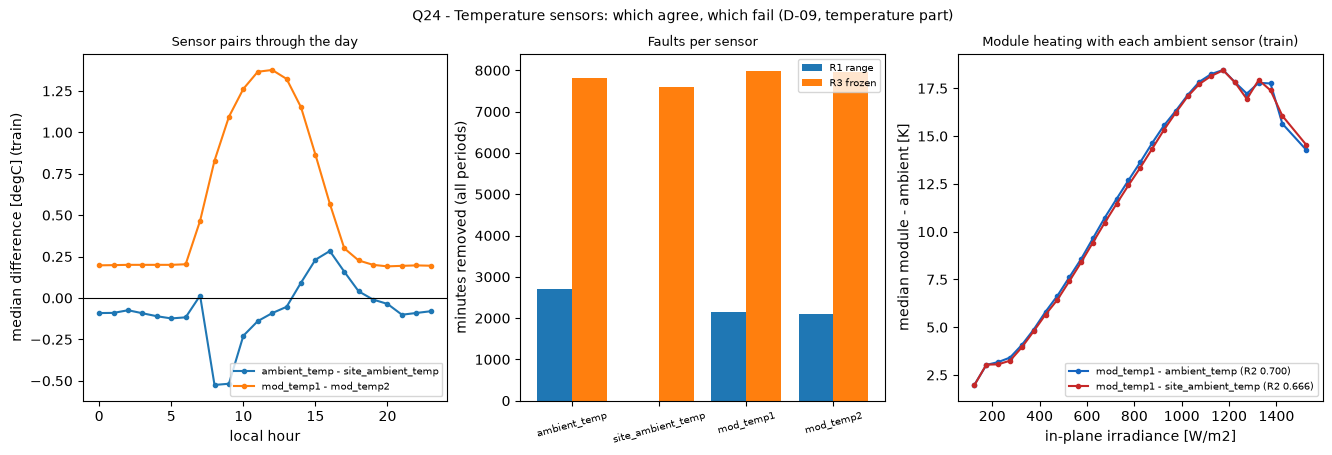

In [25]:
r = Q.q24_temperature_sensors(d)  # sensor pairs, fault rates, and module heating (train)
r.show()

**What it shows.** The two ambient sensors agree closely (r = 0.988,
median difference -0.06 K; 98 % of differences between -4.2
and +1.2 K). The meteo sensor has 2,698 fault-code
minutes that the SiteData sensor does not have, but it explains module heating slightly better
(R² 0.70 against 0.67
for module − ambient against irradiance) and shares the logger and clock of the irradiance and
module sensors. The module sensors are practically identical (r = 0.9997, median
difference +0.29 K).

**What it means.** Recommendation for D-09 (temperature): keep `ambient_temp` as the model input
(its fault codes are removed by R1) and `site_ambient_temp` for QA only. One module sensor would
be enough; stage 7 can confirm it.

### Q25 — How are the hourly variables related?

**Question.** Which measured variables move with the target? **Data.** Hourly, train, daytime, normal operation; Spearman correlation.

,variable,site_total_AC_kW,s01_inv1_AC_kW,s01_inv2_AC_kW,irradiance,pyranometer,poa_clearsky,elev,mod_temp1,mod_temp2,ambient_temp,site_ambient_temp,wind_speed,s01_inv1_DC_kW
0,site_total_AC_kW,1.000,1.000,1.000,0.986,0.984,0.917,0.870,0.661,0.643,0.175,0.178,0.182,0.999
1,s01_inv1_AC_kW,1.000,1.000,0.998,0.983,0.982,0.913,0.866,0.657,0.639,0.170,0.173,0.180,0.999
2,s01_inv2_AC_kW,1.000,0.998,1.000,0.988,0.987,0.920,0.873,0.665,0.647,0.180,0.183,0.184,0.999
3,irradiance,0.986,0.983,0.988,1.000,0.999,0.929,0.902,0.726,0.709,0.256,0.260,0.171,0.986
4,pyranometer,0.984,0.982,0.987,0.999,1.000,0.926,0.900,0.736,0.719,0.272,0.282,0.167,0.984
5,poa_clearsky,0.917,0.913,0.920,0.929,0.926,1.000,0.942,0.663,0.647,0.202,0.204,0.184,0.920
6,elev,0.870,0.866,0.873,0.902,0.900,0.942,1.000,0.784,0.769,0.391,0.387,0.196,0.874
7,mod_temp1,0.661,0.657,0.665,0.726,0.736,0.663,0.784,1.000,1.000,0.814,0.809,0.171,0.662
8,mod_temp2,0.643,0.639,0.647,0.709,0.719,0.647,0.769,1.000,1.000,0.824,0.819,0.169,0.643
9,ambient_temp,0.175,0.170,0.180,0.256,0.272,0.202,0.391,0.814,0.824,1.000,0.987,0.226,0.175


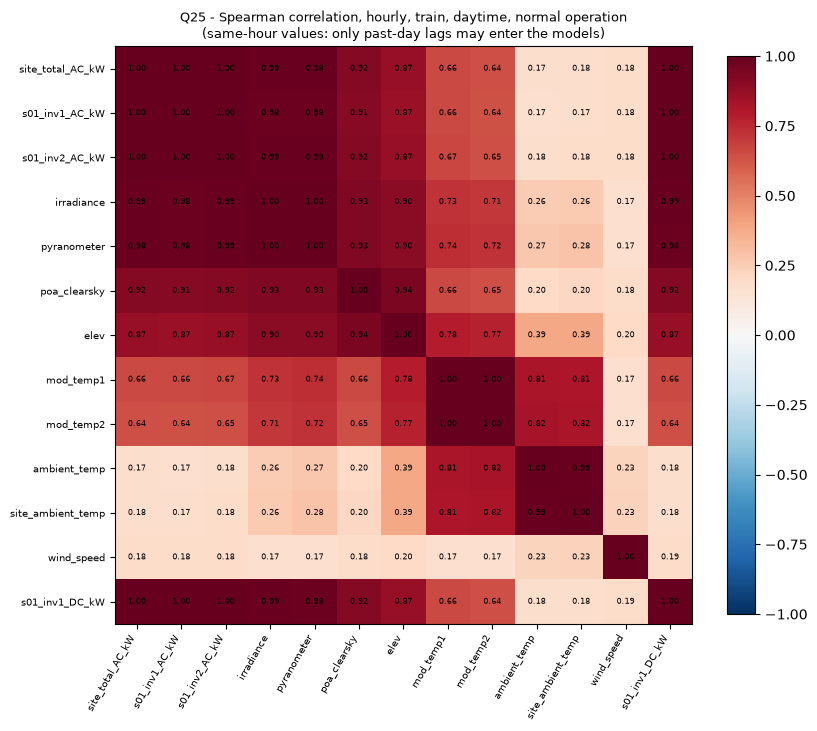

In [26]:
r = Q.q25_correlations(d)  # correlation matrix (train)
r.show()

**What it shows.** The target follows the in-plane irradiance almost one-to-one
(Spearman 0.986), much more closely than clear-sky irradiance
(0.917) or sun elevation (0.87): clouds matter. Module temperature
correlates 0.66 with output, mostly because both rise with irradiance; ambient
temperature (0.17) and wind (0.18) hardly.

**What it means.** All of these are measured at the target time and may enter the models only as
past-day lags (§6.6), so these correlations are an upper bound on what weather information could
give — not what the lags will give (Q26).

### Q26 — How much does the same hour on past days tell?

**Question.** How informative are the lag features (1, 2, 3, 7, 14 days) of the contract? **Data.** Hourly, train, daytime, normal operation.

,series,lag_days,pearson_r
0,site AC,1,0.8967
1,site AC,2,0.8740
2,site AC,3,0.8735
3,site AC,4,0.8642
4,site AC,5,0.8696
5,site AC,6,0.8686
6,site AC,7,0.8694
7,site AC,8,0.8636
8,site AC,9,0.8615
9,site AC,10,0.8579


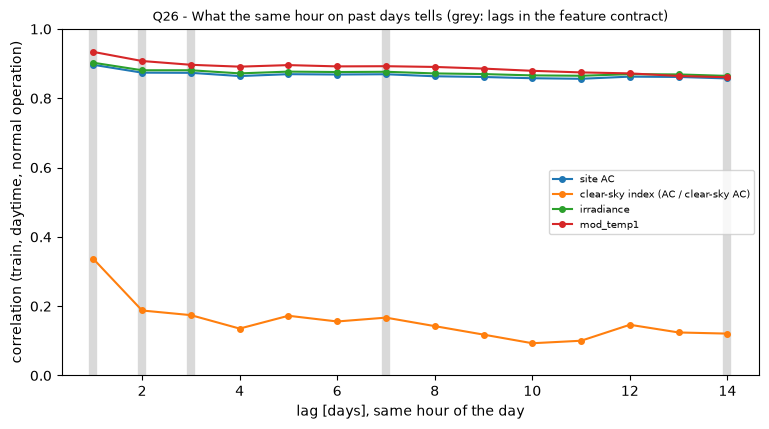

In [27]:
r = Q.q26_lags(d)  # correlation with the same hour 1-14 days earlier (train)
r.show()

**What it shows.** The same hour yesterday correlates 0.90 with today's
output, and still 0.86 two weeks earlier — but this is mostly the daily and
seasonal cycle, which the clear-sky features already describe. Once output is divided by
clear-sky output, the day-to-day persistence of the sky condition is weak:
0.34 at one day, 0.19 at two,
0.17 at seven and 0.12 at fourteen days.

**What it means.** The lags carry little information beyond the clear-sky features (consistent
with the daily persistence of 0.33 found in stage 3); weather forecasts (stage 6b) are the main
source of skill, and long lags are expected to be weak in feature selection (stage 7).

### Q27 — How cloudy is it, by season?

**Question.** How often is the sky clear, partly cloudy or overcast? **Data.** Hourly, train, daytime, normal operation; kt = measured irradiance / clear-sky POA.

col_0,season,overcast,partly cloudy,clear,hours,median_kt
0,DJF,3.6,18.8,77.5,2141,1.073
1,MAM,1.9,10.2,87.9,1852,1.083
2,JJA,0.3,1.9,97.8,1986,1.084
3,SON,0.8,8.0,91.2,2551,1.086


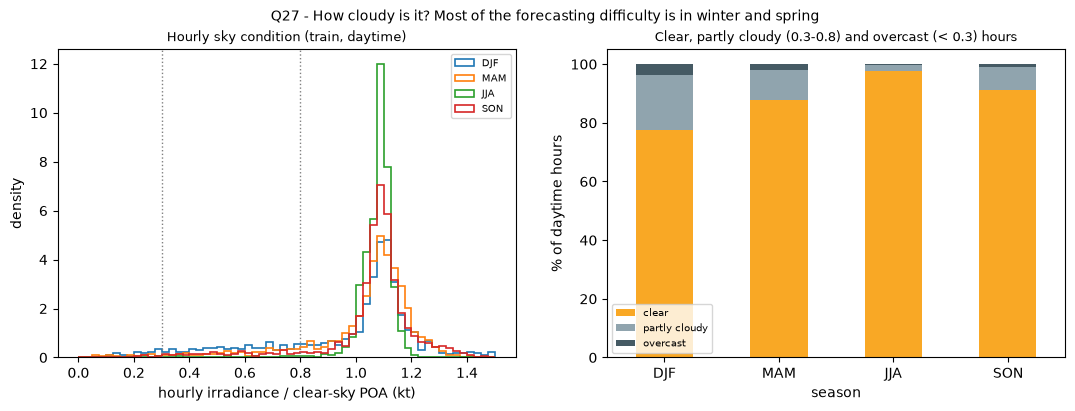

In [28]:
r = Q.q27_sky_conditions(d)  # hourly sky condition by season (train)
r.show()

**What it shows.** Most daytime hours are clear (kt ≥ 0.8): 77.5 % in
winter, 87.9 % in spring, 97.8 % in summer and
91.2 % in autumn; overcast hours (kt < 0.3) are rare (3.6 %
in winter). The median kt is about 1.08: the in-plane sensor reads about
8 % above the Ineichen clear-sky model on typical clear hours.

**What it means.** Forecast errors will concentrate in winter and spring; summer is nearly
deterministic. The scale of the clear-sky reference is decided in stage 6 (D-11).

### Q28 — Is there a weekday effect?

**Question.** Does production depend on the day of the week (`is_weekend`, `day_of_week` are in the feature contract)? **Data.** Daily clear-sky index, train, complete days in normal operation.

,day,days,median_daily_index,mean_daily_index
0,Mon,118,0.8003,0.7802
1,Tue,115,0.7931,0.7713
2,Wed,117,0.7932,0.7723
3,Thu,111,0.8129,0.7847
4,Fri,116,0.7999,0.7725
5,Sat,110,0.7992,0.7756
6,Sun,118,0.7935,0.7664


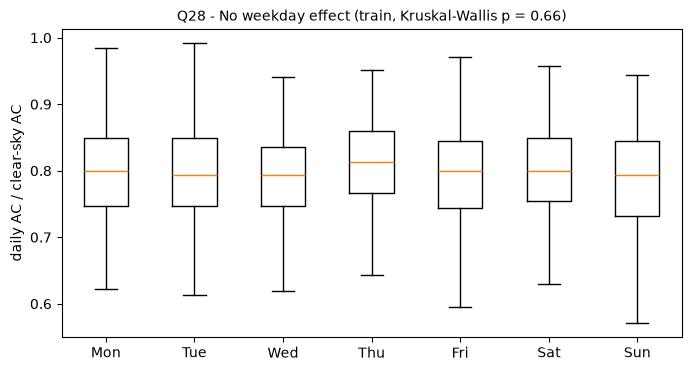

In [29]:
r = Q.q28_weekday(d)  # daily index by day of week (train)
r.show()

**What it shows.** The daily clear-sky index does not differ between days of the week
(Kruskal–Wallis p = 0.66 over 805 days; the medians lie within
0.020).

**What it means.** A PV plant does not follow a work week. `is_weekend` and `day_of_week` can only
add noise; stage 7 is expected to drop them.

### Q29 — Long-term trend: degradation, soiling or sensor drift?

**Question.** Does the plant's performance change over the years, and is it the plant or the sensor? **Data.** Hourly, normal operation; trends estimated on train, validation and test shown for description only.

,month,split,hours,performance_index,plant_vs_clear_sky_p90,sensor_vs_clear_sky_p90
0,2021-09,train,67,2.9003,0.8579,1.1171
1,2021-10,train,66,2.8675,0.8624,1.1101
2,2021-11,train,101,2.8733,0.8918,1.1468
3,2021-12,train,72,2.8929,0.8940,1.0862
4,2022-01,train,72,2.8948,0.9583,1.1532
5,2022-02,train,60,2.9337,0.9256,1.1278
6,2022-03,train,70,2.9088,0.8986,1.1178
7,2022-04,train,70,2.8827,0.8893,1.1410
8,2022-05,train,72,2.8419,0.8907,1.1726
9,2022-06,train,72,2.8477,0.8273,1.1072


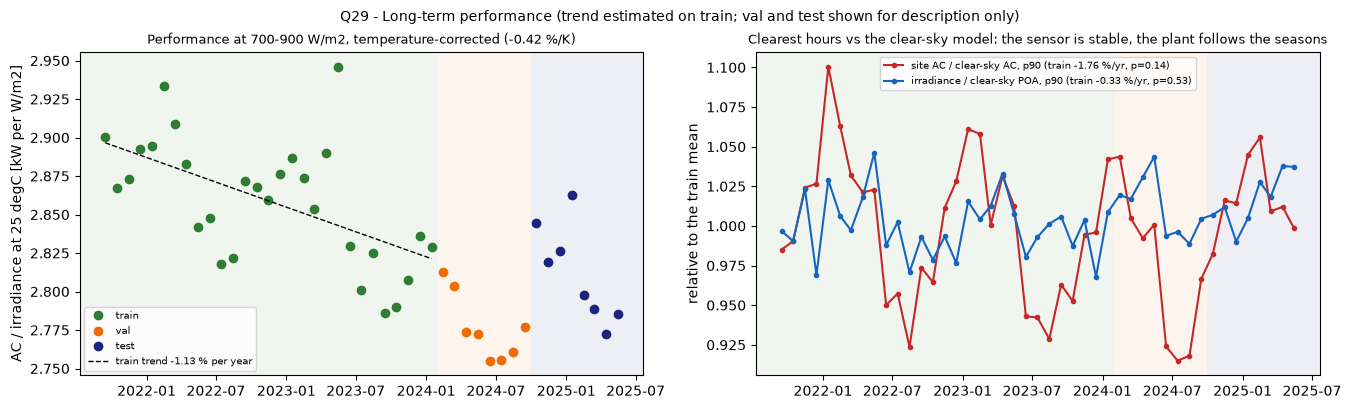

In [30]:
r = Q.q29_long_term(d)  # monthly performance index and clear-sky checks
r.show()

**What it shows.** At 700–900 W/m², corrected to 25 °C, output per unit irradiance
declines by 1.1 % per year over train
(p = 0.001), on top of a seasonal swing of about
3 %. Against the clear-sky model, which does not depend on the
sensor, the irradiance sensor is stable (-0.3 % per year,
p = 0.53: no drift), while the plant's clearest-hour output points the
same way (-1.8 % per year) but is dominated by the seasons
(p = 0.14). In January the clearest-hour output was
0.958 → 0.924 → 0.907 → 0.910 over the four winters.

**What it means.** A slow decline of about 1 % per year, plus soiling or cleaning cycles, is
plausible; it is small next to weather errors and not monotonic into the test period, so no trend
feature is proposed. It is recorded as a limitation (a possible small level bias of the direct
target in test).

### Q30 — Why are the remaining tags not used?

**Question.** Could any unused tag help, and does any need cleaning? **Data.** Stage 4, all periods (descriptive).

,tag,evidence,conclusion
0,precipitation,"max 0.00, minutes > 0: 0, minutes < 0: 1760",never records rain in 45 months (the site has ...
1,soil,monthly median > 1 until 2023-06; then 0.00 or...,sensor stops reporting during the data; undocu...
2,soiling01,monthly median > 1 until 2024-06; then 0.00 or...,sensor stops reporting during the data; undocu...
3,soiling02,monthly median > 1 until 2024-06; then 0.22 or...,sensor stops reporting during the data; undocu...
4,wind_speed / wind_direction,held >= 30 min: 2.7 % / 0.5 % of daytime minut...,"measured at the target time (EXCL), no lag in ..."
5,"kVar, PF",PF = 1.000 in 47.8 % of minutes; kVar follows ...,"grid control, not weather: no information on a..."
6,inverter states,code 3: 49.3 %; code 1: 48.9 %; code 5: 1.1 %;...,status at the target time (EXCL); used only by...
7,iec_sp_q,"p1 -14129.8, median 355.1, p99 13748.0",grid setpoint for reactive power / voltage: no...
8,iec_sp_v,"p1 38.8, median 166.0, p99 170.1",grid setpoint for reactive power / voltage: no...
9,iec_sp_pf,"p1 -1.0, median 0.0, p99 1.0",grid setpoint for reactive power / voltage: no...


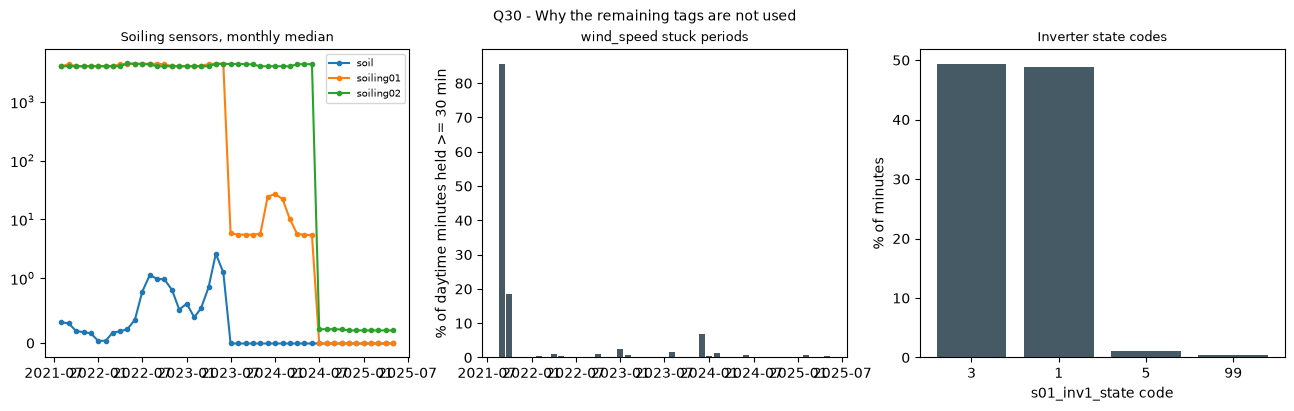

In [31]:
r = Q.q30_unused_tags(d)  # evidence for each unused tag
r.show()

**What it shows.** Precipitation never records rain in 45 months (maximum
0.0, 0 positive minutes; the site does
get rain), so the gauge is not reporting. The three soiling sensors freeze or fall to zero during
the data (last active 2023-06, 2024-06
and 2024-06) and have no documented units. Wind speed and
direction are measured at the target time (EXCL) and stick for long periods
(2.7 % of daytime minutes). Reactive power and power factor
follow the grid operator's setpoint (PF exactly 1.000 in 48 % of minutes);
the IEC Q/V/PF setpoints are grid control. Inverter status codes are used only by flag F3.

**What it means.** None of these is a candidate model input, and cleaning them beyond R1 on wind
speed would serve no purpose.

### Q31 — How do the splits differ? (descriptive only)

**Question.** What do the three splits contain? **Data.** Hourly, daytime, all splits. *Descriptive only — used for no decision.*

,split,daytime_hours,calendar_months,hours_DJF,hours_MAM,hours_JJA,hours_SON,mean_ac_kw,median_kt,clear_hour_pct,mean_ac_over_clear_sky
0,train,9698,"1,2,3,4,5,6,7,8,9,10,11,12",2290,2214,2341,2853,1508.9,1.083,81.1,0.787
1,val,2902,"2,3,4,5,6,7,8,9",290,1108,1170,334,1511.3,1.101,84.9,0.791
2,test,2580,"1,2,3,4,5,10,11,12",857,1108,0,615,1483.4,1.109,82.1,0.788


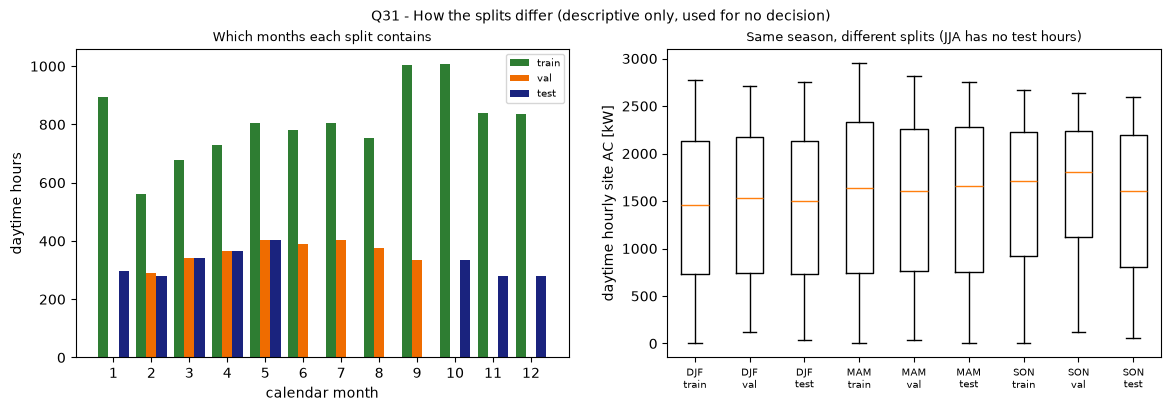

In [32]:
r = Q.q31_splits(d)  # months and production levels by split
r.show()

**What it shows.** Test covers calendar months 1,2,3,4,5,10,11,12 — it has no
summer hours (0 hours in June–August), the season in which forecasting is
easiest (Q27). The mean daytime output is similar in the three splits
(1,509 / 1,511 / 1,483 kW),
as is the share of clear hours (81 / 85 /
82 %).

**What it means.** Test errors will be higher than a full-year average would be; comparisons with
the original remain fair because the split is the same, and per-season reporting (§6.9) makes the
difference visible.

## Summary — the evidence for each cleaning rule

| Rule | Threshold | Evidence (train) | Verdict |
|---|---|---|---|
| R1 range | temperatures −20…60/90 °C, irradiance −20…1,600 W/m², power −20…1,897 kW | limits in empty regions (Q04, Q05) | ✅ not tuned |
| R1 margin | ±1 min (minute source), ±15 min (polled) | blends next to temperature faults (Q06); polled: interpolation over one poll period | ✅ |
| R2 offset | −20…0 W/m² → 0 | night offset ≥ -7.8 W/m², never negative in daylight (Q07) | ✅ |
| R3 frozen | 30 min (ambient 60), non-zero power | plateau of run lengths (Q08); freezes hit all sensors at once (Q09) | ✅ insensitive |
| R3 margin | ±1 / ±15 min | resume minutes are blends (Q10) | ✅ |
| R4 night zero | ≤ 5 kW below the horizon → 0 | no night noise exists; acts on tiny twilight output, 238 kWh in total (Q11) | ⚠️ kept as a definition; justification corrected |
| R5 night stale | > 5 kW below −6° → NaN | all such minutes are frozen values (Q11) | ✅ |
| R6 dead DC | DC = 0 with AC > 100 kW | one dead sensor, March 2023 (Q12) | ✅ |
| R7 scale fault | ratio outside 0.9–1.1, per day **and per hour** | two populations, 1.00 and 0.75; the fault also switches within a day (Q13) | ✅ **changed: F-21** |
| F1 downtime | AC < 20 kW, sun > 5°, irradiance > 150 | stops are a separate mode; 20–100 kW is empty (Q14) | ✅ |
| F2 curtailment | setpoint < 100 %, **not a non-integer drift > 10 min** | steps cut output; the 2022 drift did not (Q15) | ✅ **changed: F-20** |
| F3 derate | status 5/6 ≥ 30 min, or stable windowed ratio < 0.85 | modes 0.99 and 0.74/1.30 with empty valleys; stable fractions (Q16) | 🆕 **new: F-22** |
| Hourly | coverage 45/60, op-limited share 0.05 | hours complete or empty; few hours near the threshold (Q17) | ✅ insensitive |

**For the next stages.** Clear-sky index unstable at low sun → denominator of k (D-11, Q22);
winter-morning row shading (Q22); the observed peak is 85 % of
the 3,449 kW capacity (A-08, Q23);
keep `ambient_temp`, one module sensor suffices (D-09, Q24); past-day lags carry little beyond
the clear-sky features (Q26); no weekday effect (Q28); a slow decline of about 1 % per year
(Q29); test has no summer (Q31).

**Reproduce.** `python -m solarpv.data.clean` (stage 5), `python -m solarpv.eda.quality`, then
`python scripts/make_quality_notebook.py`. Checks: T-31 (`tests/contracts/test_quality_eda_output.py`).